In [2]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')

from pathlib import Path
import numpy as np
import polars as pl
from joblib import load
from matplotlib import pyplot as plt
from light_curves import read_fits_lc, preprocess_lc
from frequency_domain_features import compute_lombscargle_periodogram

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Classification results parquets 

In [39]:
plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')
training_set = "training_df_try8"

df_training_set = pl.read_parquet(plato_data_directory / f'{training_set}.parquet').select(['path', 'label', 'GaiaID']).with_columns(
    pl.col('path').str.split('/').list.get(-1).alias('name'),
    pl.col('path').str.split('/').list.get(-1).str.split('-').list.get(2).alias('sector')
)

model_path = Path('../results/classifications') / training_set
feature_config = load(model_path / 'feature_config.pkl')
clf = load(model_path / 'model_xgboost.pkl')
le = load(model_path / 'label_encoder.pkl')

In [54]:
#%%time

from tqdm.notebook import tqdm
from training import prepare_features_for_classification, prepare_predictions_dataframe

for sector_path in tqdm(sorted(Path('../results/features/').glob('s*'))):
    save_path = Path(f'../results/classifications/{sector_path.name}/')
    if (save_path / 'predictions.parquet').exists():
        continue
    df_inference_features = pl.read_parquet(sector_path)    
    df_inference_features = df_inference_features.with_columns(
        pl.col('path').str.split('/').list.get(-1).alias('name')
    ).join(df_training_set.select(['name']), on='name', how='anti').drop('name') # remove training sources
    df_inference_features, df_dropped = prepare_features_for_classification(df_inference_features, **feature_config)
    paths = df_inference_features['path'].to_numpy()
    X = df_inference_features.drop(['path']).to_numpy()
    df_pred = prepare_predictions_dataframe(clf, le, X, paths, drop_nans=True)
    #display(df_pred.head())    
    save_path.mkdir(parents=True, exist_ok=True)
    df_pred.write_parquet(save_path / 'predictions.parquet')

  0%|          | 0/26 [00:00<?, ?it/s]

In [62]:
df_all_preds = pl.read_parquet('../results/classifications/s*/*.parquet', columns=['path', 'best_rf_class', 'best_rf_proba', 'rf_entropy'])
df_all_preds.shape

(37506979, 4)

In [57]:
# Histogram 
df_all_preds.group_by('best_rf_class').len().sort('best_rf_class').with_columns((100*pl.col('len')/pl.col('len').sum()).alias('percent'))

best_rf_class,len,percent
str,u32,f64
"""APERIODIC""",85510,0.227984
"""CONTACT_ROT""",1712460,4.56571
"""DSCT_BCEP""",604532,1.611785
"""ECLIPSE""",948131,2.527879
"""GDOR_SPB""",348331,0.92871
"""INSTRUMENT/JUNK""",29554569,78.797519
"""RRLYR_CEPH""",75160,0.200389
"""SOLARLIKE""",4178286,11.140023


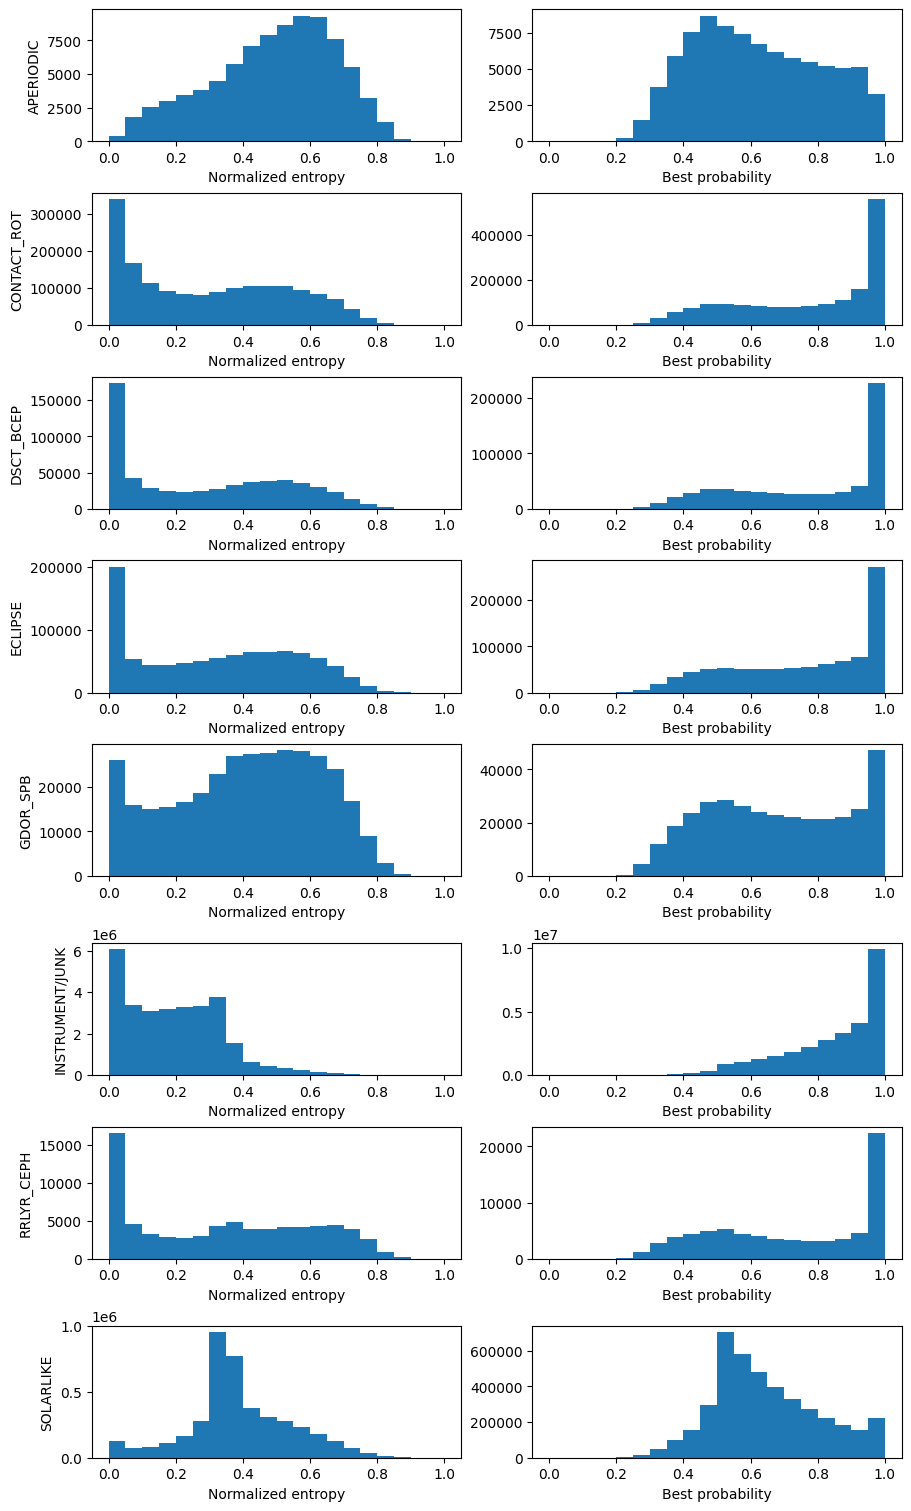

In [58]:
best_class = df_all_preds['best_rf_class'].to_numpy()
best_proba, entropy = df_all_preds.drop('best_rf_class').to_numpy().T

fig, axs = plt.subplots(len(le.classes_), 2, figsize=(9, 15), constrained_layout=True)
for name, ax in zip(le.classes_, axs):
    mask = best_class == name
    ax[0].hist(entropy[mask], range=(0, 1), bins=20)
    ax[0].set_ylabel(name, fontsize=10)
    ax[0].set_xlabel('Normalized entropy')
    ax[1].hist(best_proba[mask], range=(0, 1), bins=20)
    ax[1].set_xlabel('Best probability')

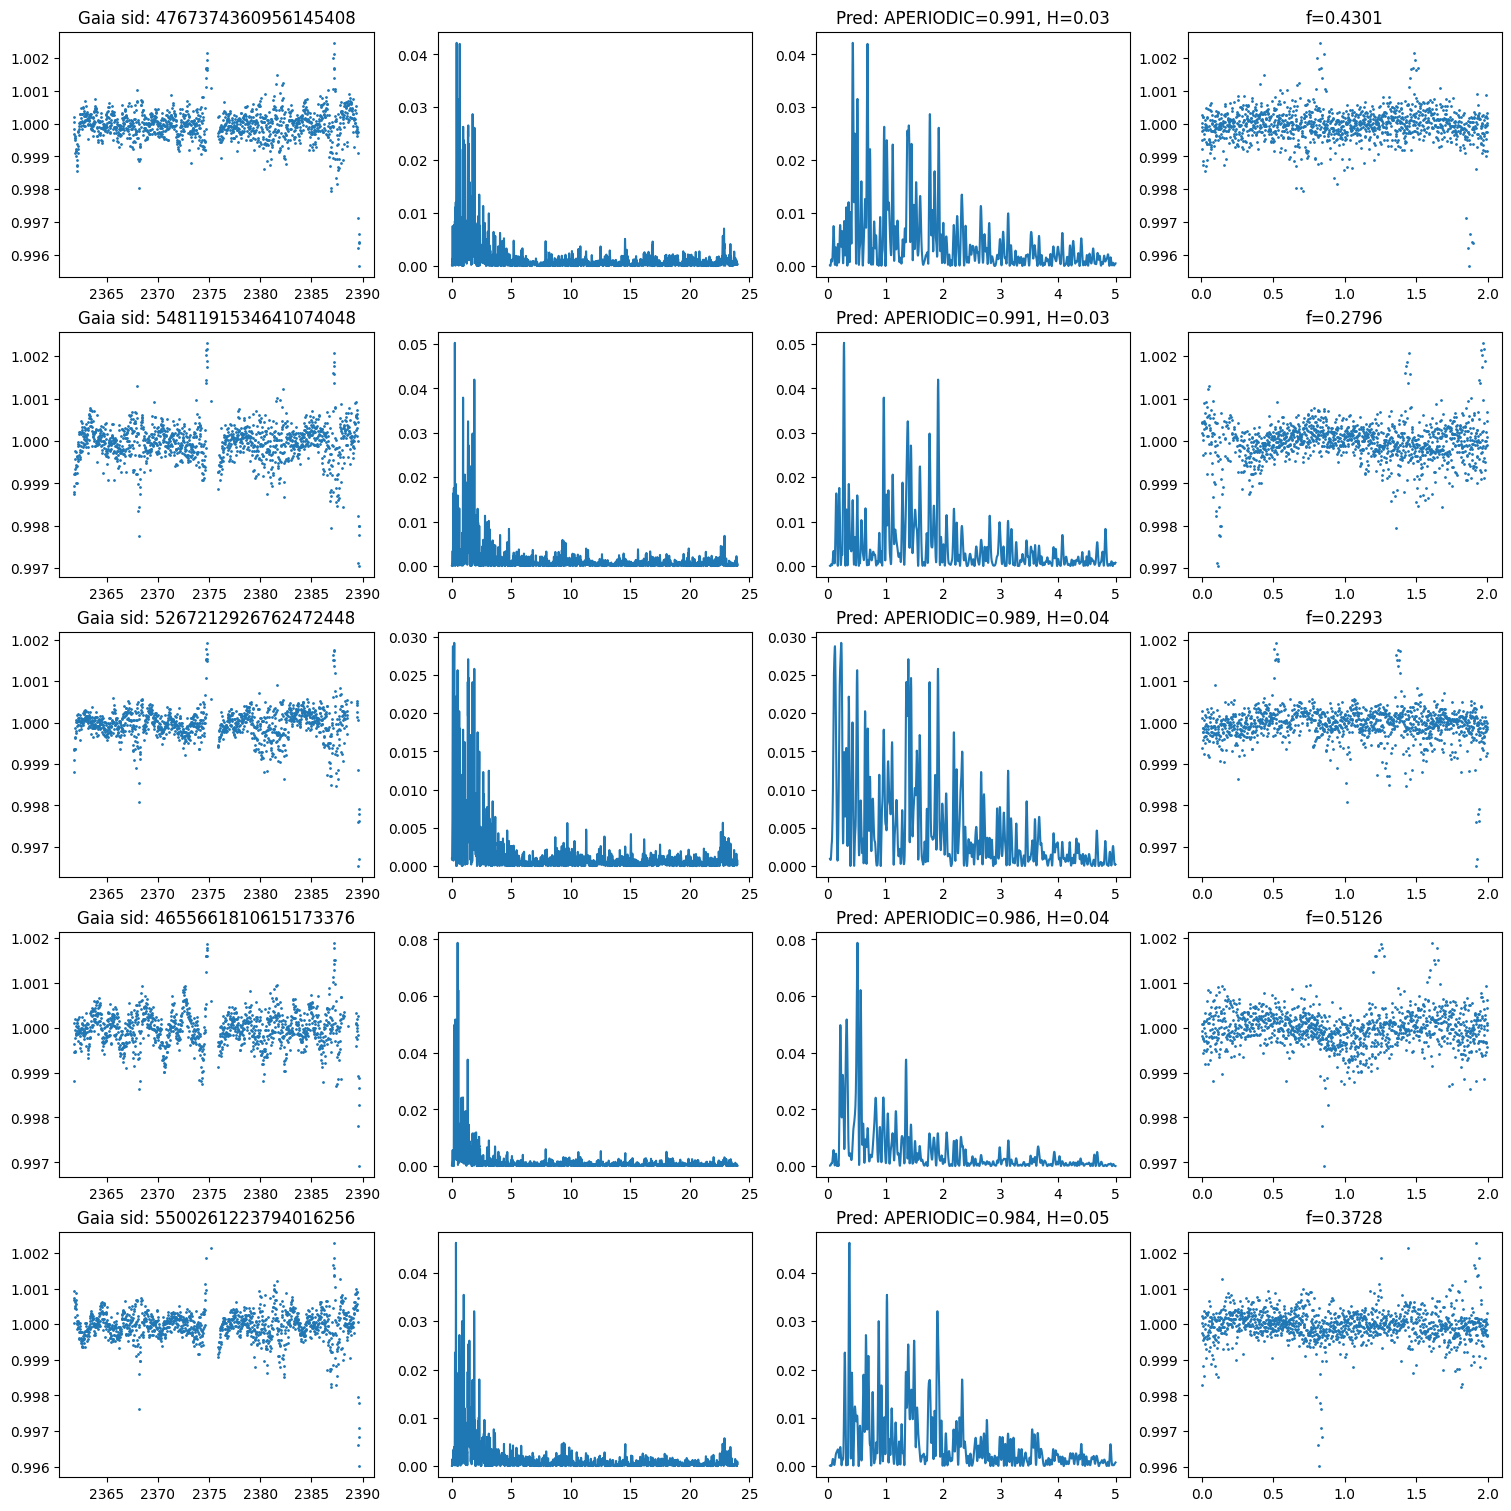

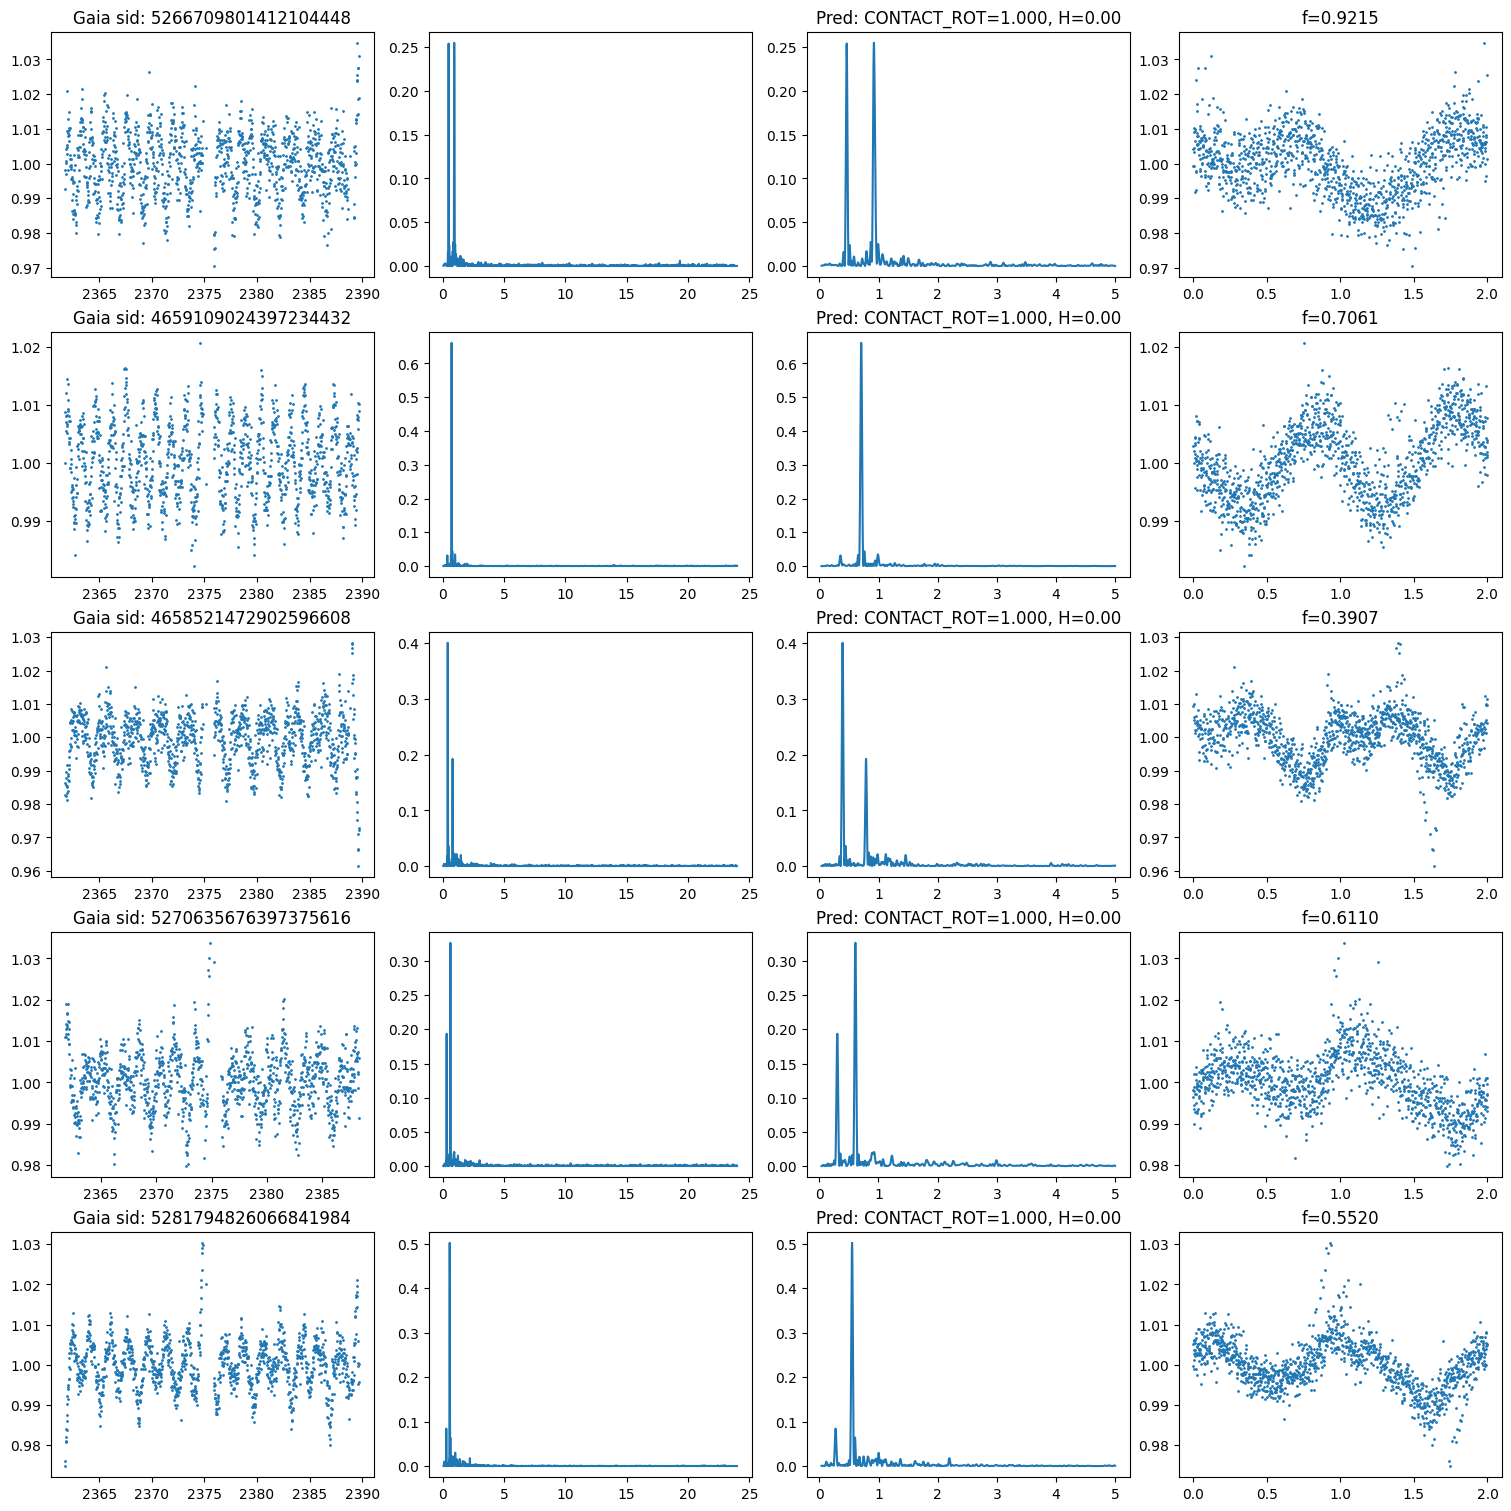

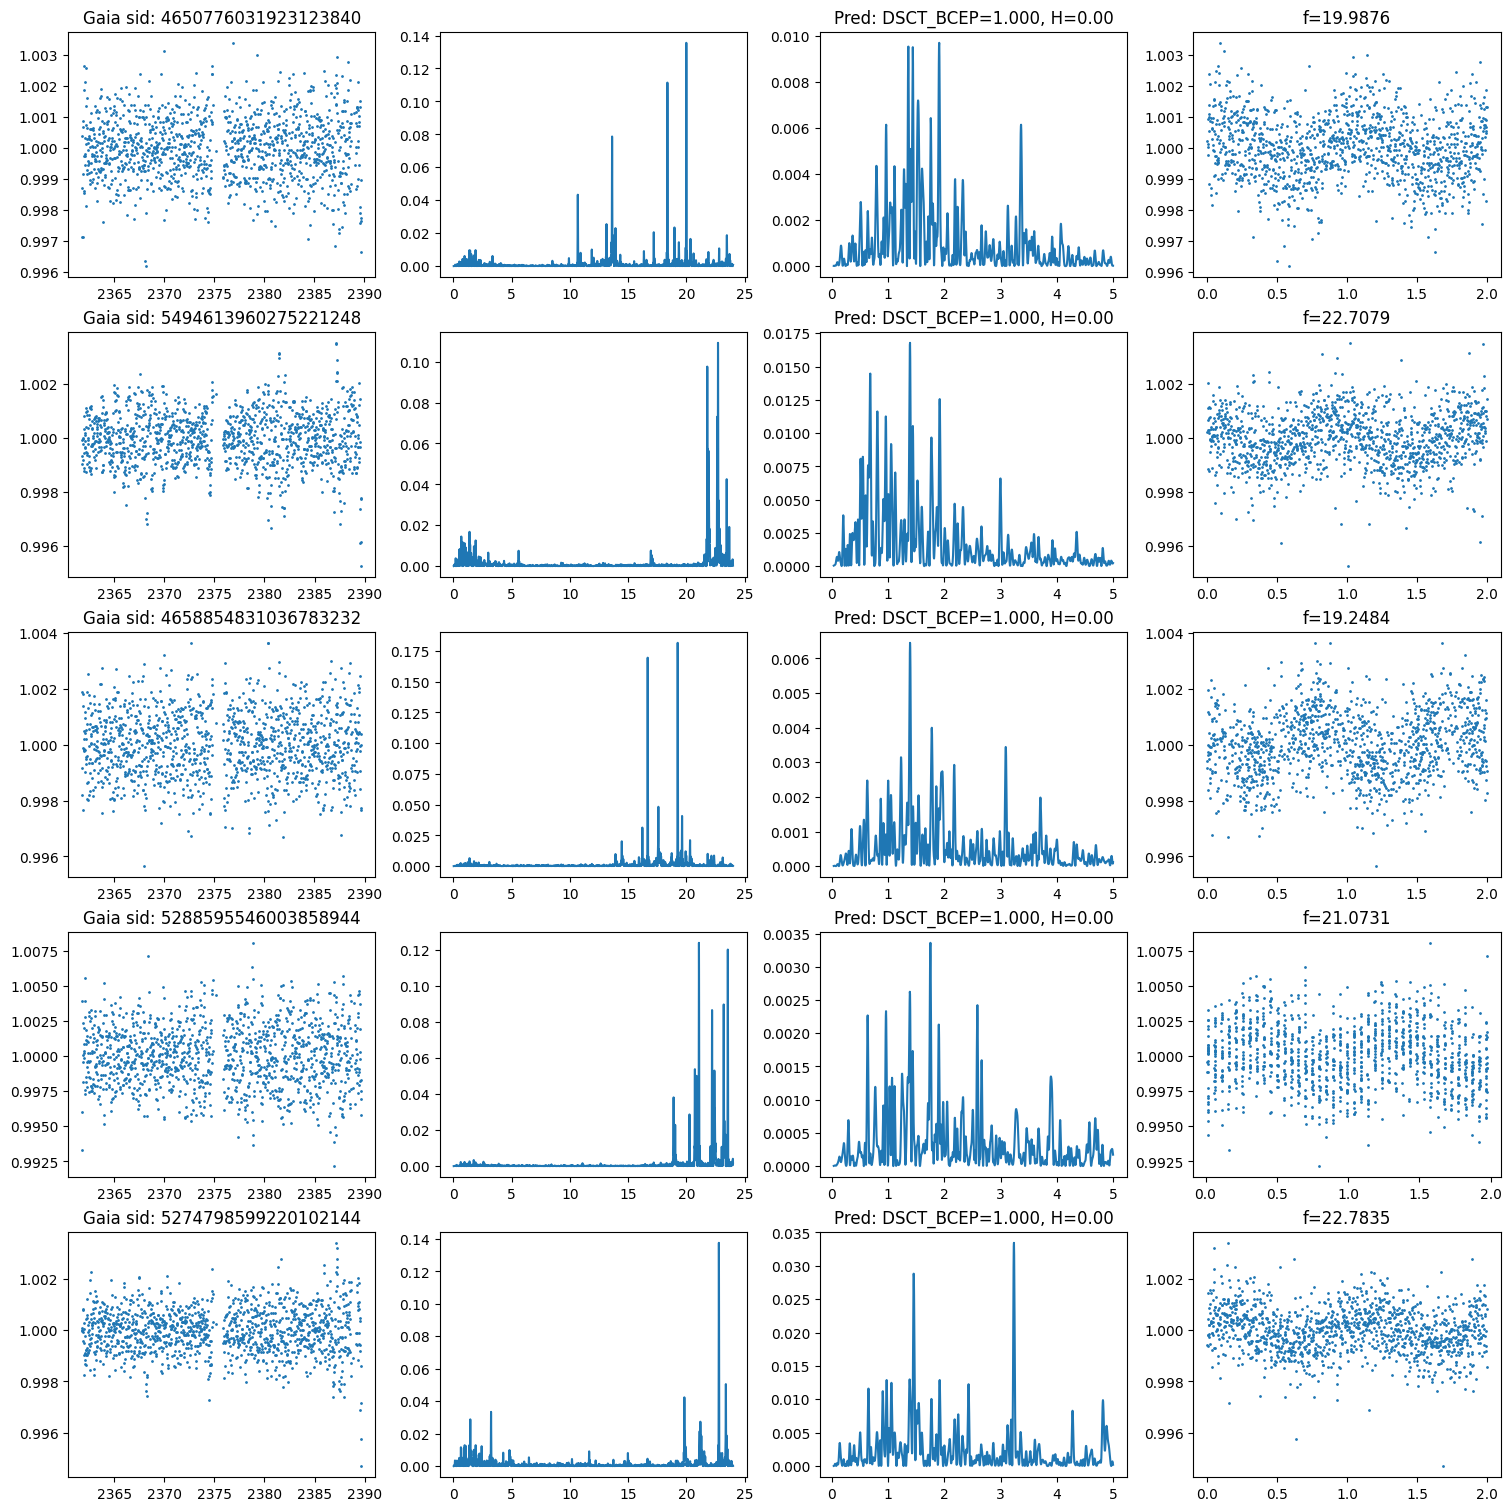

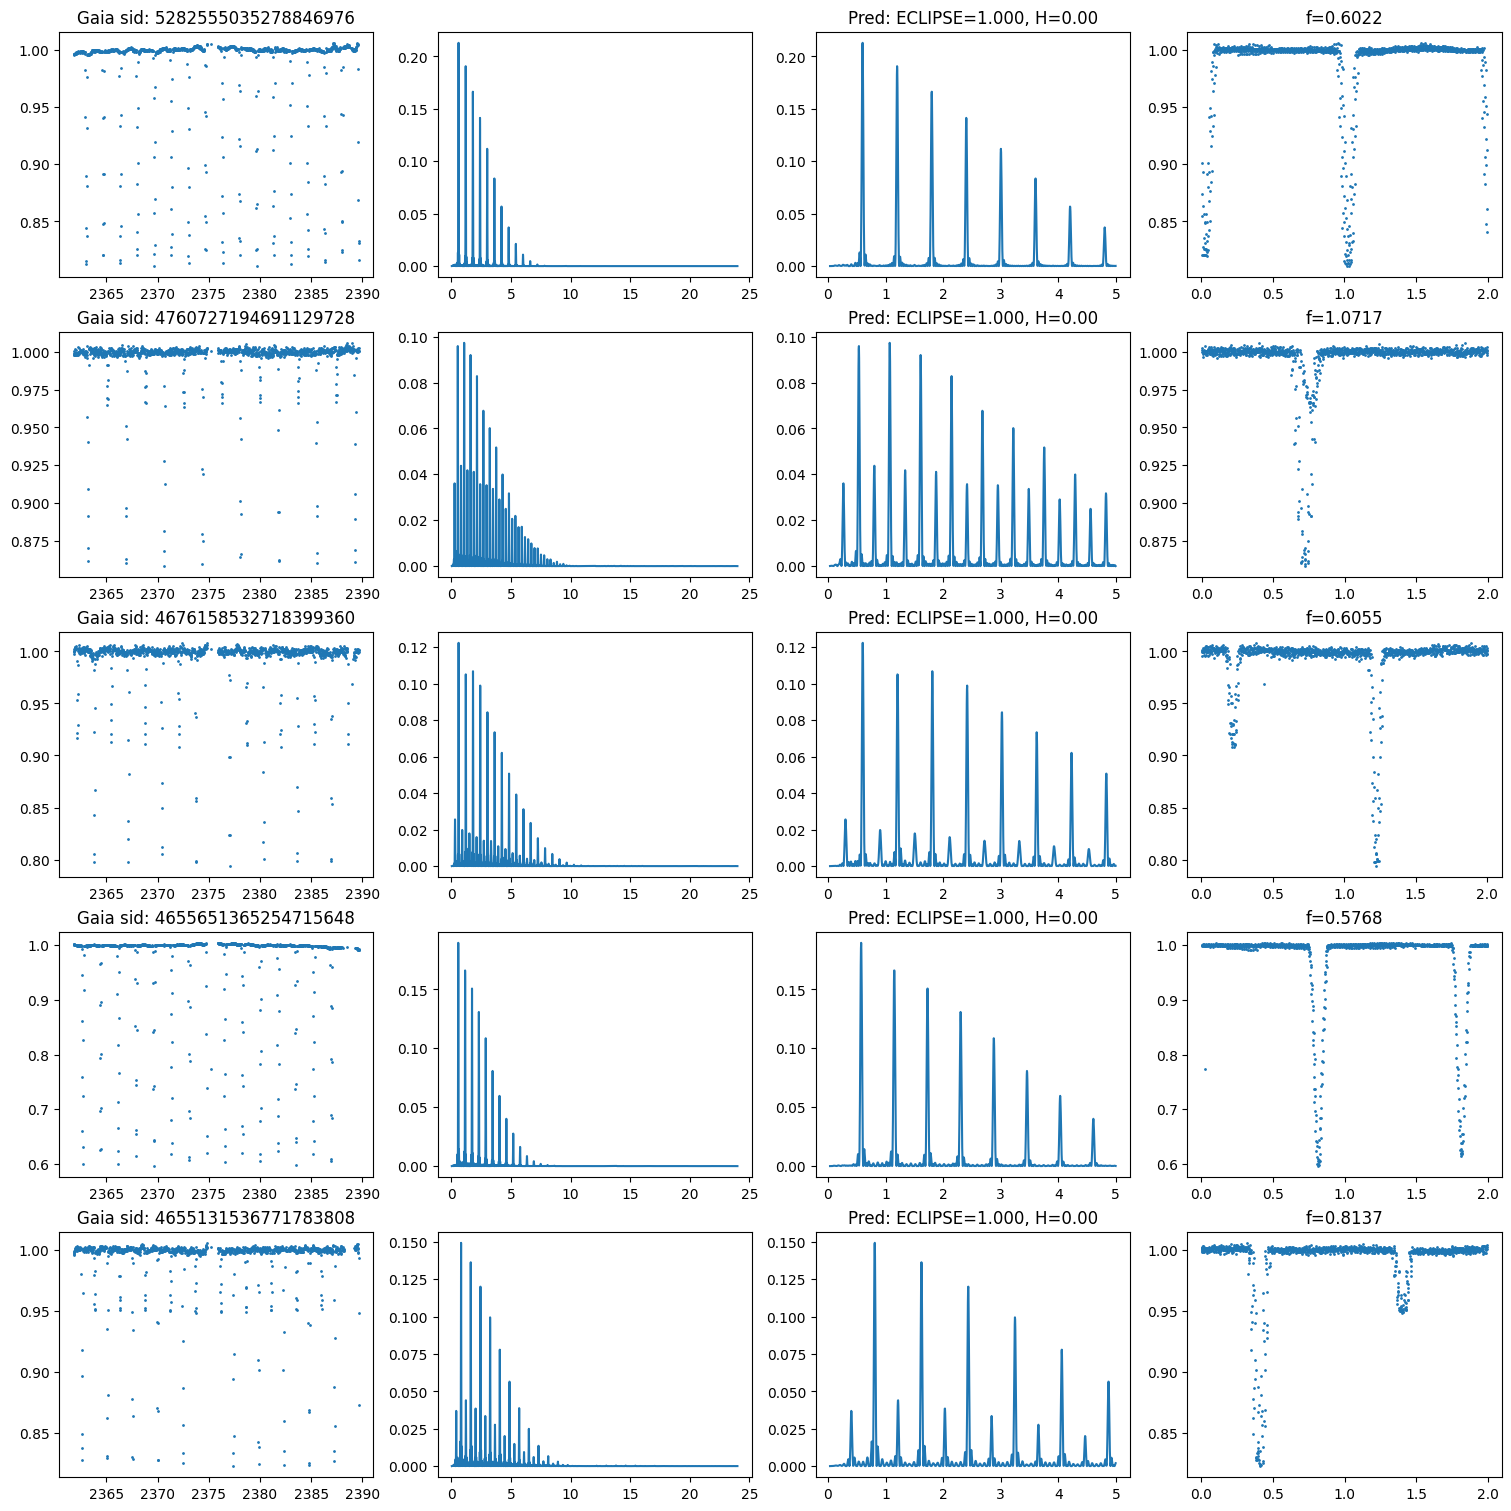

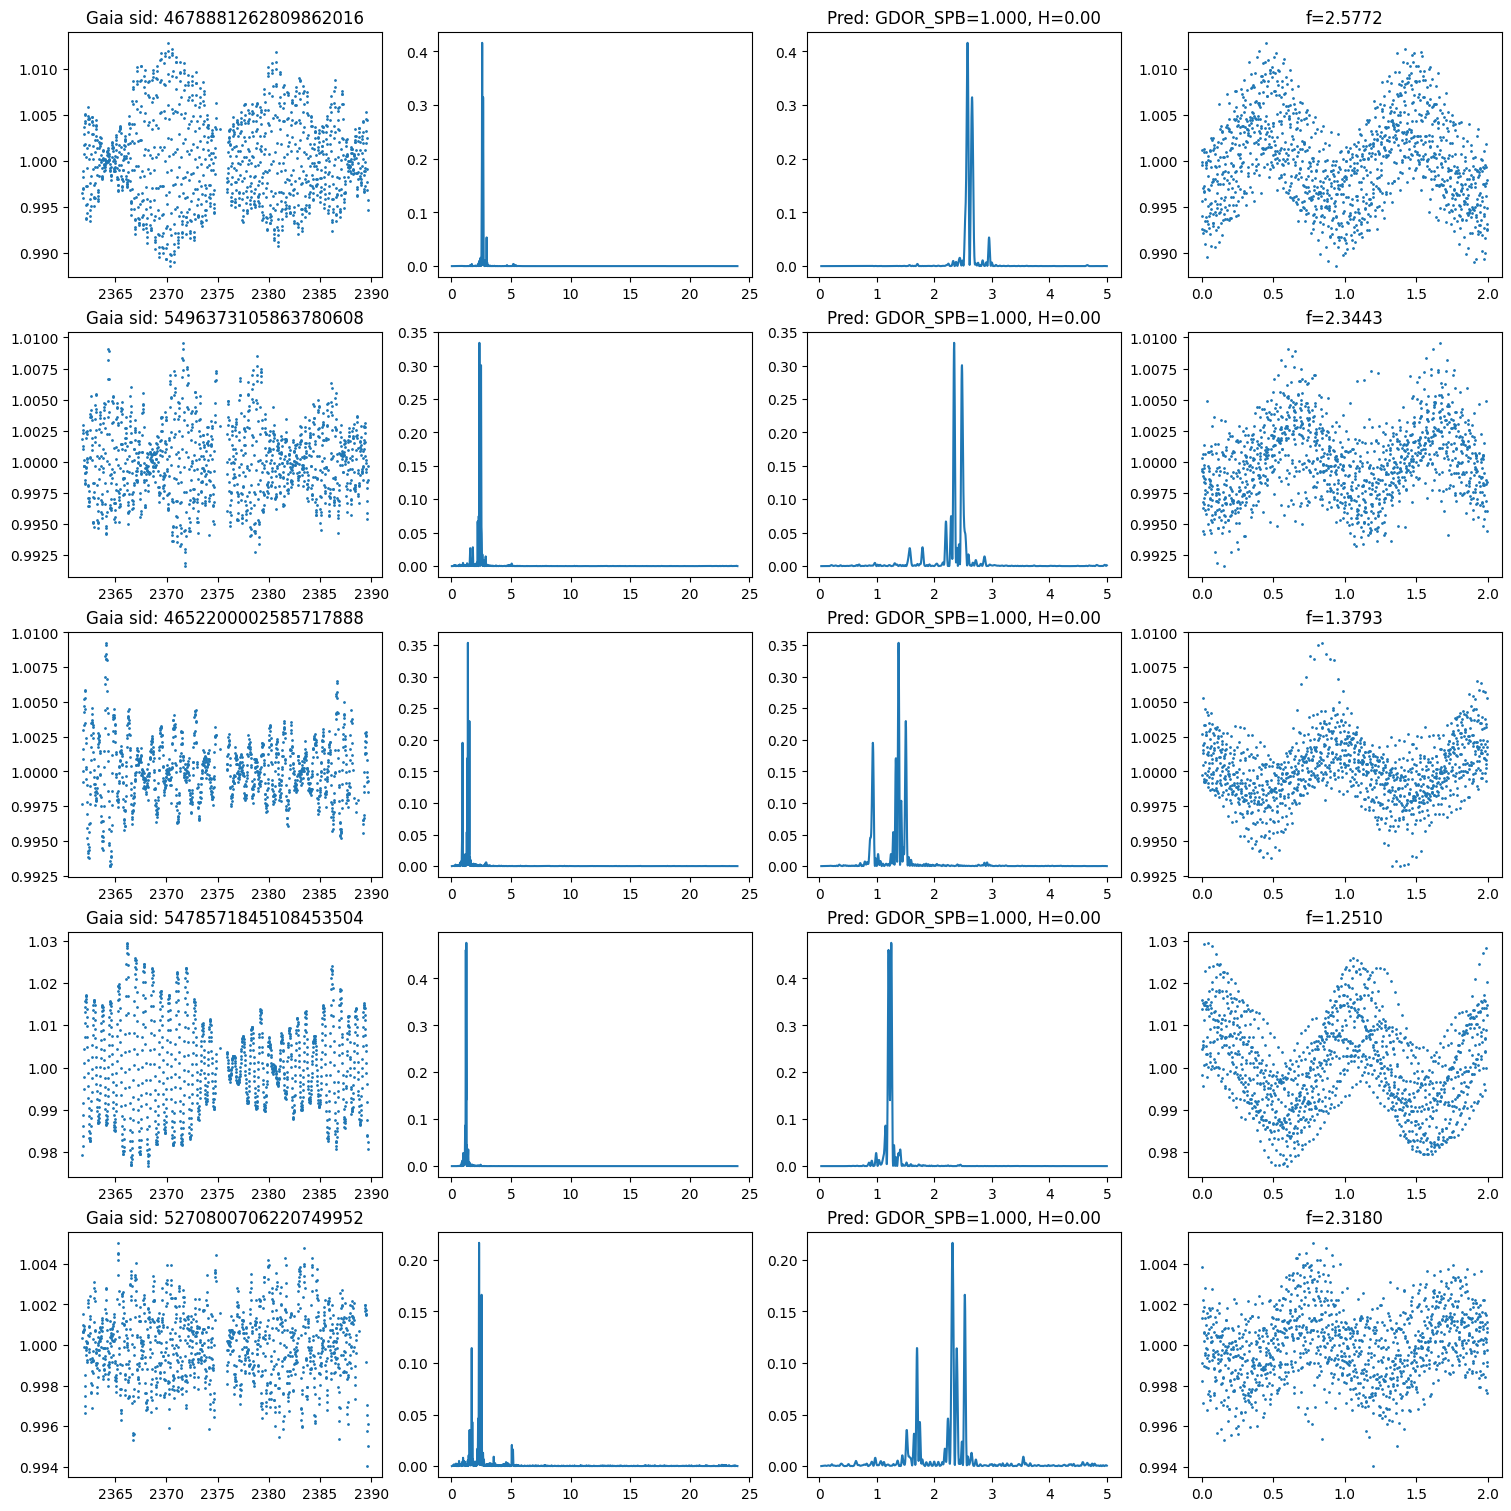

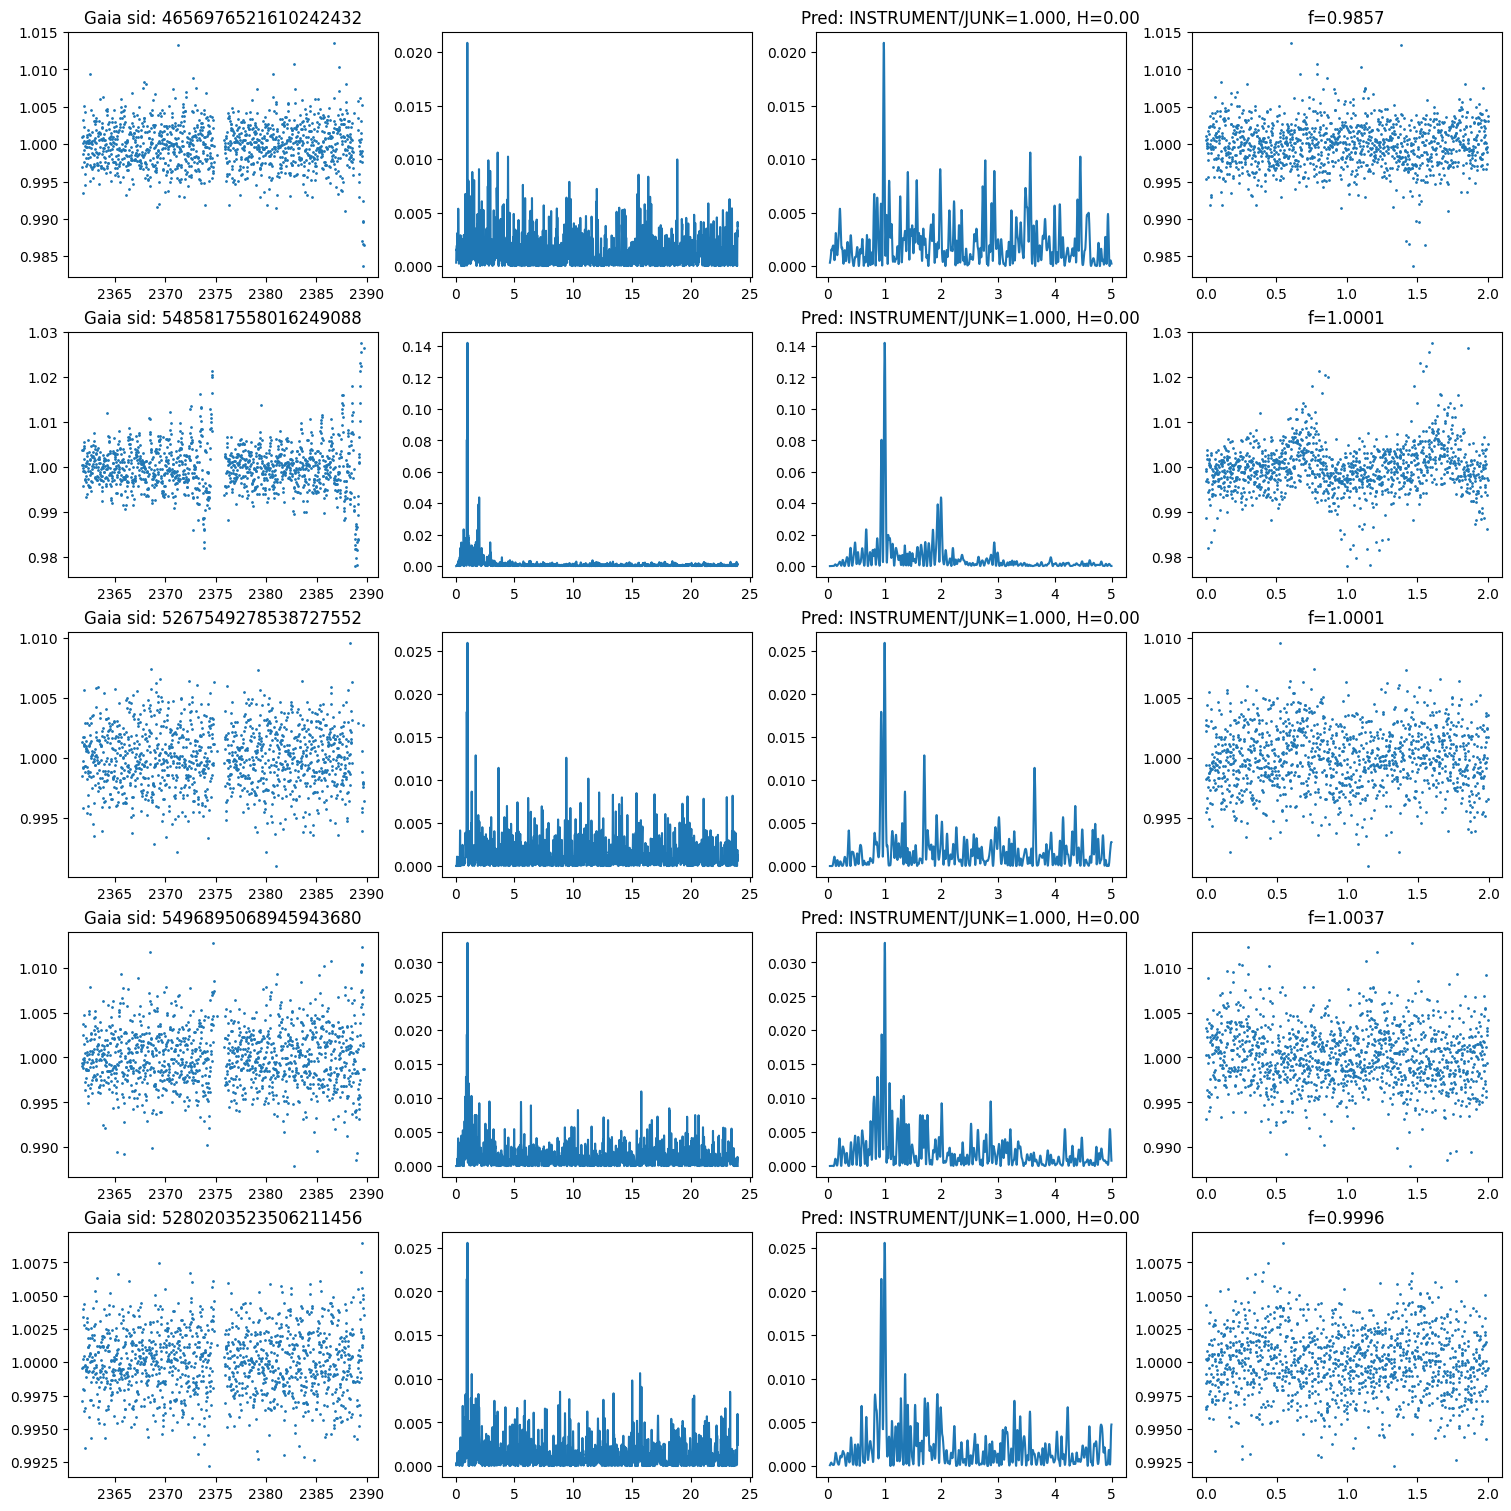

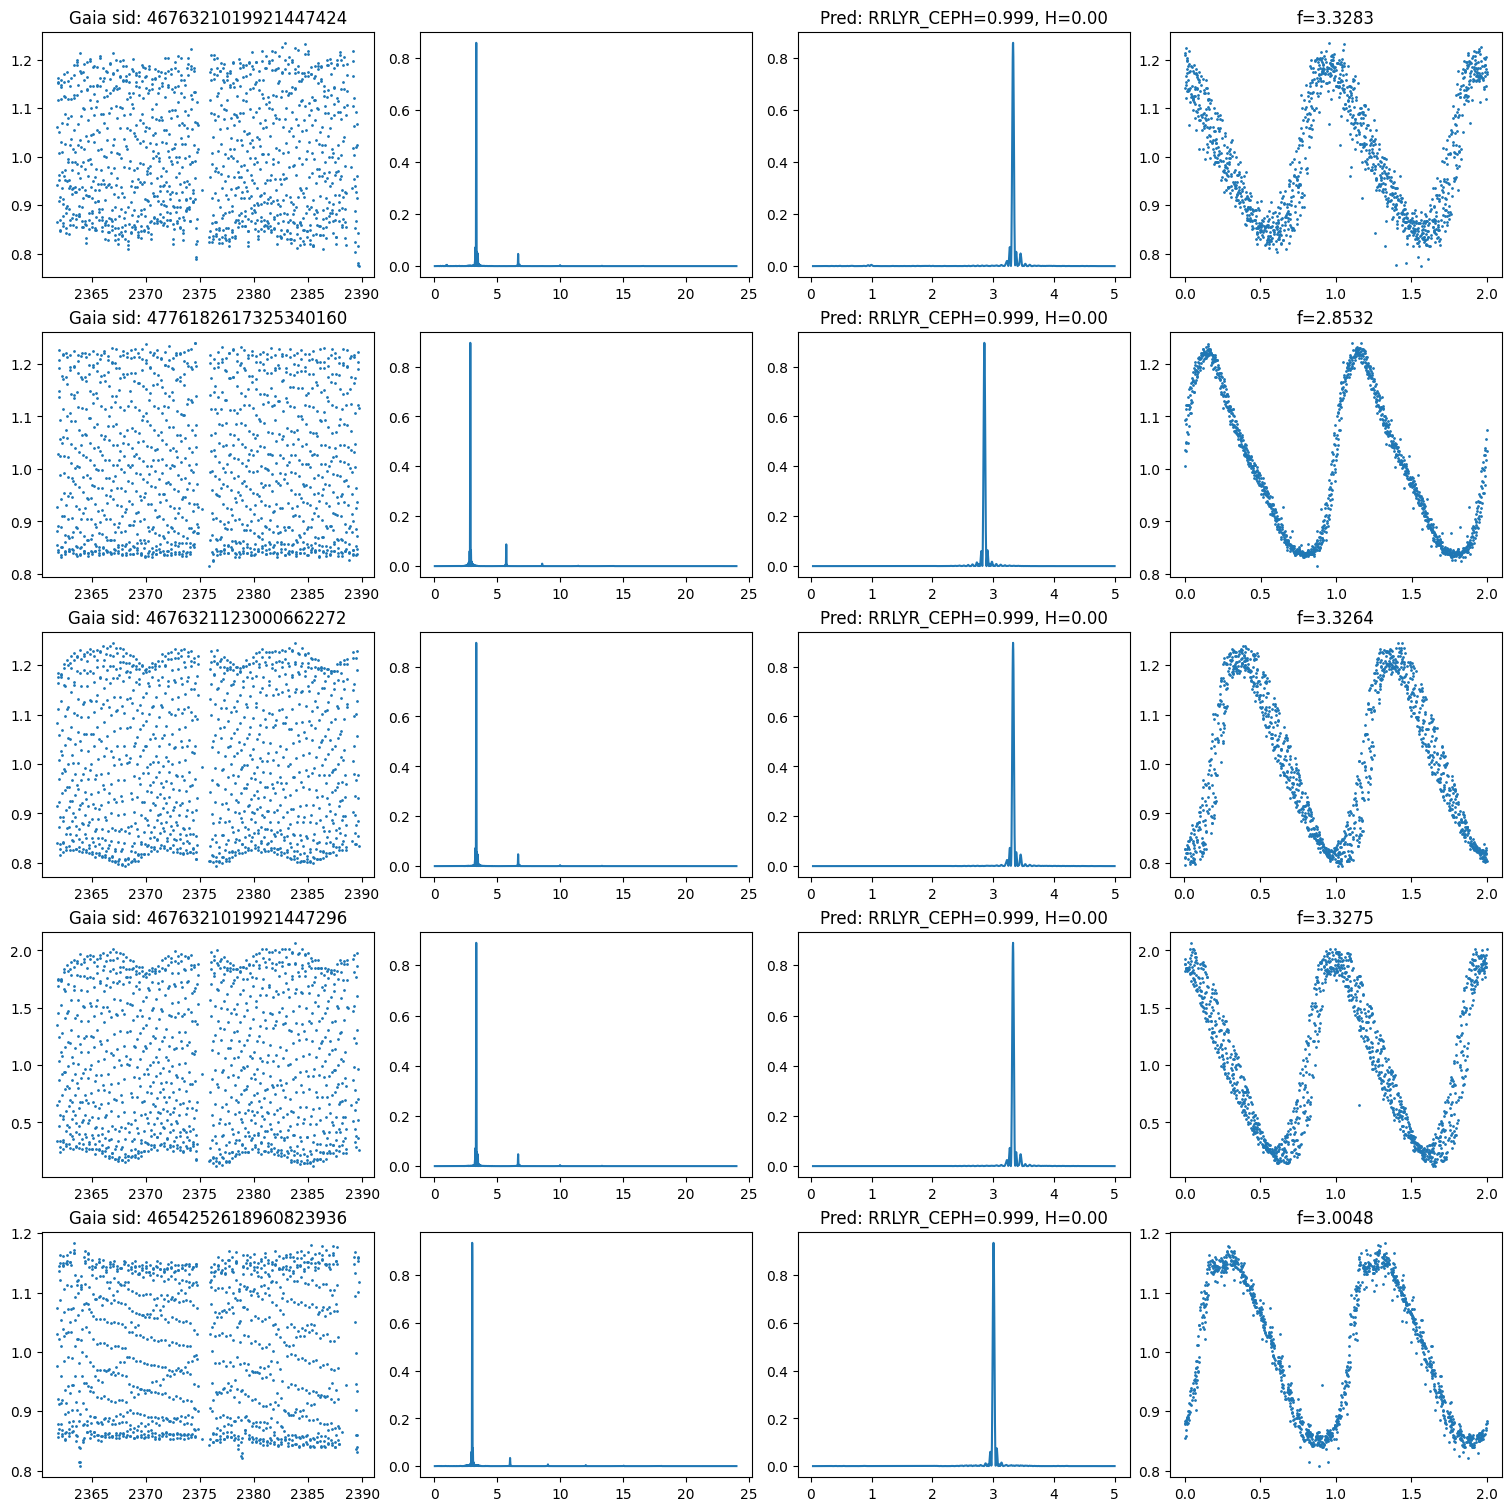

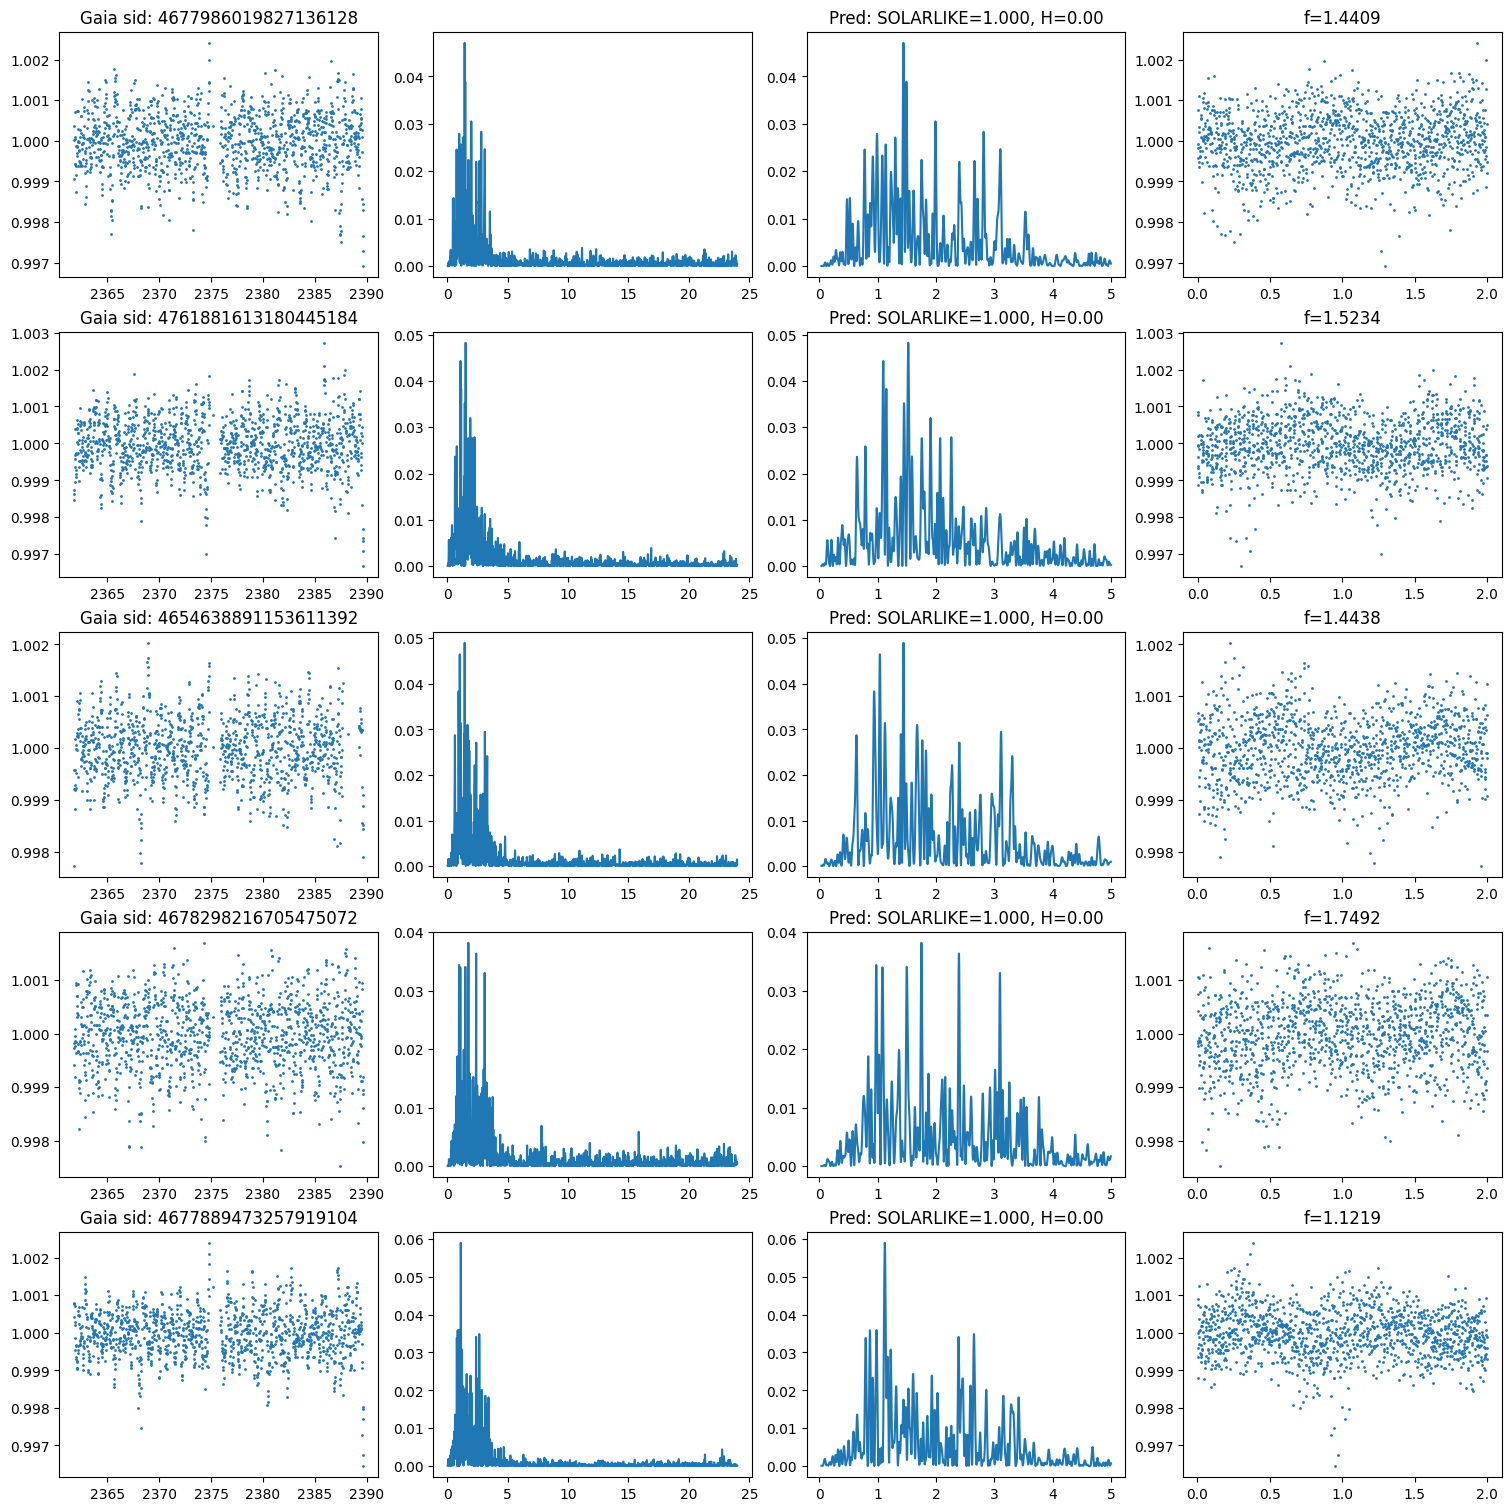

In [59]:
# Top 20 per class
for analysis_class in le.classes_:
    sub_df = df_pred.sort(analysis_class, descending=True).head(5)
    n_plots = sub_df.height
    fig, axs = plt.subplots(max(2, n_plots), 4, figsize=(15, 3*n_plots), constrained_layout=True, sharex=False)
    for row, ax in zip(sub_df.iter_rows(named=True), axs):
        path_, proba, entropy = row['path'], row[analysis_class], row['rf_entropy']
        sid, sector = path_.split('-')[2:4]
        ax[0].set_title(f"Gaia sid: {sid}")
        #ax[1].set_title(f"True: {true_class}={proba_true:0.3f}")
        ax[2].set_title(f"Pred: {analysis_class}={proba:0.3f}, H={entropy:0.2f}")
        time, flux, sector = read_fits_lc(path_)
        #ax[0].scatter(time, flux, s=1)
        time_pre, flux_pre = preprocess_lc(time, flux, sector)
        ax[0].scatter(time_pre, flux_pre, s=1)
        freq, ampl, _ = compute_lombscargle_periodogram(time_pre, flux_pre)
        best_freq = freq[np.argmax(ampl)]
        ax[-3].plot(freq, ampl)
        ax[-2].plot(freq[freq<5], ampl[freq<5])
        ax[-1].set_title(f"f={best_freq:0.4f}")
        ax[-1].scatter(np.mod(time_pre, 2/best_freq)*best_freq, flux_pre, s=1)

In [60]:
df_all_features = pl.read_parquet('../results/features/s*/*.parquet', columns=['path', 'ls_frequency_fundamental', 'ls_amplitude_fundamental'])
df_all_features.shape

(37506987, 3)

In [63]:
df_all_features = df_all_features.join(df_all_preds, on='path')

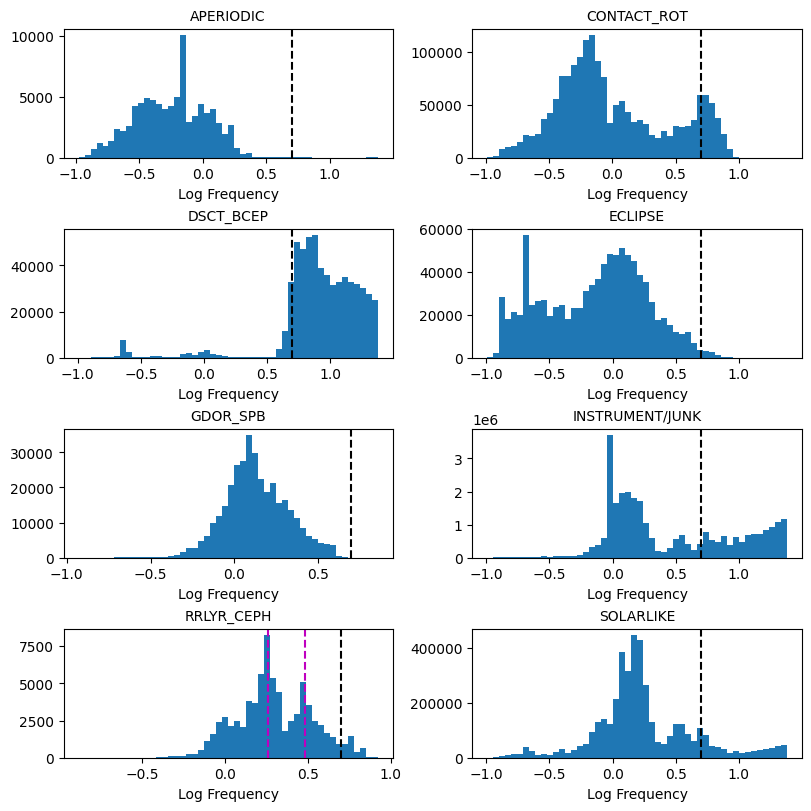

In [75]:
fig, axs = plt.subplots(4, 2, figsize=(8, 8), constrained_layout=True)
for name, ax in zip(le.classes_, axs.ravel()):
    mask = best_class == name    
    ax.hist(np.log10(df_all_features.filter(pl.col('best_rf_class').eq(name))['ls_frequency_fundamental'].to_numpy()), bins=50)
    ax.set_title(name, fontsize=10)
    ax.axvline(np.log10(5), ls='--', c='k')
    if name == 'RRLYR_CEPH':
        ax.axvline(np.log10(1/0.55), ls='--', c='m')
        ax.axvline(np.log10(1/0.33), ls='--', c='m')
    ax.set_xlabel('Log Frequency')
    

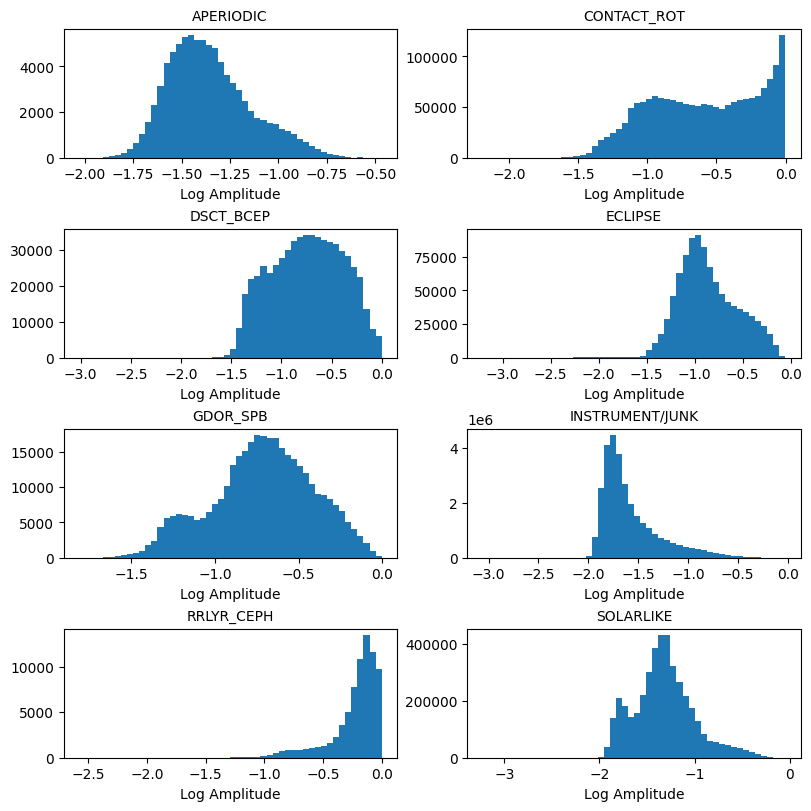

In [76]:
fig, axs = plt.subplots(4, 2, figsize=(8, 8), constrained_layout=True)
for name, ax in zip(le.classes_, axs.ravel()):
    mask = best_class == name    
    ax.hist(np.log10(df_all_features.filter(pl.col('best_rf_class').eq(name))['ls_amplitude_fundamental'].to_numpy()), bins=50)
    ax.set_title(name, fontsize=10)    
    ax.set_xlabel('Log Amplitude')
    

## Exploring dual classes

In [40]:
c1, c2 = 'DSCT_BCEP', 'GDOR_SPB'

df_dual_class = pl.scan_parquet('../results/classifications/s*/*.parquet').filter(
    pl.col(c1).gt(0.4) & pl.col(c2).gt(0.25) & pl.col('INSTRUMENT/JUNK').lt(0.05) & pl.col('SOLARLIKE').lt(0.05)  & pl.col('APERIODIC').lt(0.05)
).collect()
df_dual_class

path,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE,best_rf_class,rf_entropy,best_rf_proba
str,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64
"""/STER/mamsie/tess/TIC/plato_fo…",0.000966,0.027556,0.697297,0.005137,0.250916,0.009961,0.00003,0.008136,"""DSCT_BCEP""",0.392632,0.697297
"""/STER/mamsie/tess/TIC/plato_fo…",0.000232,0.034678,0.414502,0.020094,0.501106,0.005662,0.000028,0.023697,"""GDOR_SPB""",0.493683,0.501106
"""/STER/mamsie/tess/TIC/plato_fo…",0.000146,0.140369,0.53682,0.0,0.269092,0.033703,0.000006,0.019864,"""DSCT_BCEP""",0.556045,0.53682
"""/STER/mamsie/tess/TIC/plato_fo…",0.020321,0.015519,0.42937,0.015124,0.459217,0.012031,0.0,0.048418,"""GDOR_SPB""",0.542155,0.459217
"""/STER/mamsie/tess/TIC/plato_fo…",0.000173,0.055826,0.629231,0.000004,0.265287,0.030898,0.0,0.018581,"""DSCT_BCEP""",0.474954,0.629231
"""/STER/mamsie/tess/TIC/plato_fo…",0.010725,0.053039,0.558652,0.0,0.327789,0.021221,0.000006,0.028568,"""DSCT_BCEP""",0.518735,0.558652
"""/STER/mamsie/tess/TIC/plato_fo…",0.010915,0.04208,0.573057,0.000264,0.311253,0.025338,0.0,0.037093,"""DSCT_BCEP""",0.520556,0.573057
"""/STER/mamsie/tess/TIC/plato_fo…",0.005217,0.021889,0.48841,0.015,0.442813,0.020137,0.000085,0.006448,"""DSCT_BCEP""",0.479333,0.48841


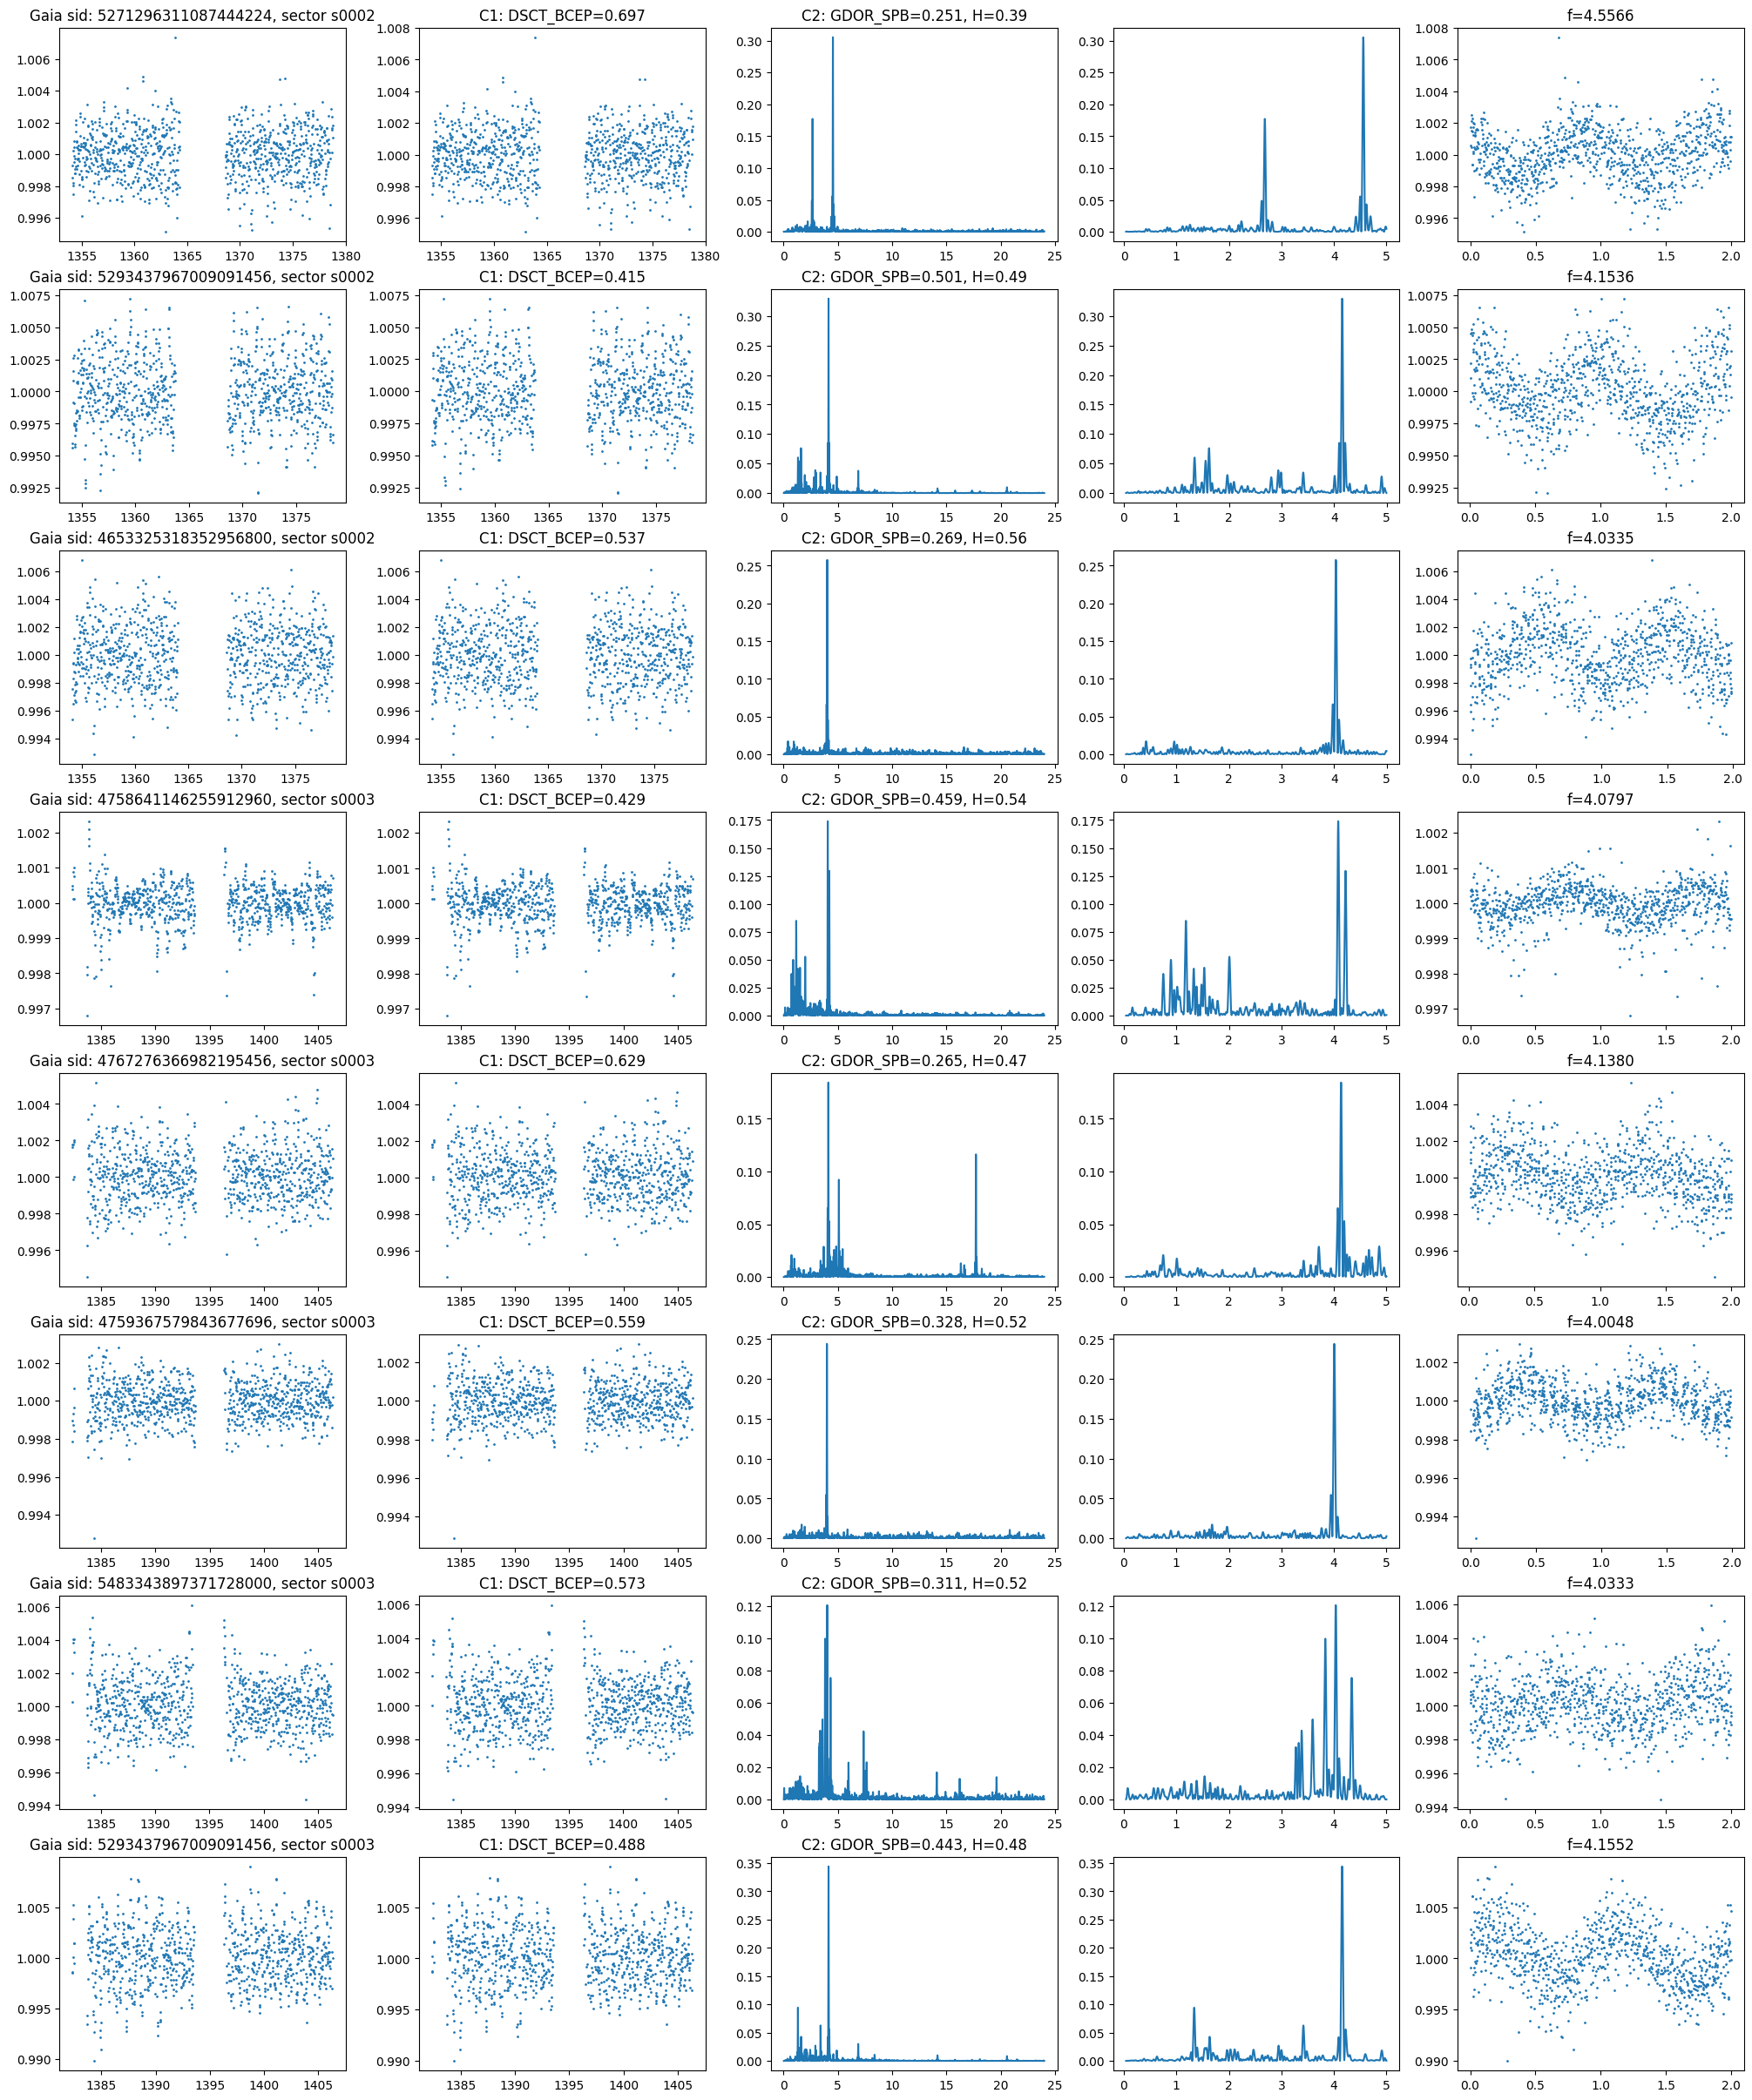

In [41]:
n_plots = min(20, df_dual_class.height)
fig, axs = plt.subplots(max(2, n_plots), 5, figsize=(20, 3*n_plots), constrained_layout=True, sharex=False)
for row, ax in zip(df_dual_class.iter_rows(named=True), axs):
    path_, proba1, proba2, entropy = row['path'], row[c1], row[c2], row['rf_entropy']
    sid, sector = path_.split('-')[2:4]
    ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
    ax[1].set_title(f"C1: {c1}={proba1:0.3f}")
    ax[2].set_title(f"C2: {c2}={proba2:0.3f}, H={entropy:0.2f}")
    time, flux, sector = read_fits_lc(path_)
    ax[0].scatter(time, flux, s=1)
    time_pre, flux_pre = preprocess_lc(time, flux, sector)
    ax[1].scatter(time_pre, flux_pre, s=1)
    freq, ampl, _ = compute_lombscargle_periodogram(time_pre, flux_pre)
    best_freq = freq[np.argmax(ampl)]
    ax[2].plot(freq, ampl)
    ax[3].plot(freq[freq<5], ampl[freq<5])
    ax[4].set_title(f"f={best_freq:0.4f}")
    ax[4].scatter(np.mod(time_pre, 2/best_freq)*best_freq, flux_pre, s=1)

# Joining with neural net predictions

In [42]:
labels = clf.classes_.copy()
labels[5] = 'JUNK'
labels

array(['APERIODIC', 'CONTACT_ROT', 'DSCT_BCEP', 'ECLIPSE', 'GDOR_SPB',
       'JUNK', 'RRLYR_CEPH', 'SOLARLIKE'], dtype=object)

In [43]:
df_s1_nnet = []
for file in sorted(Path('/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/').rglob('*.csv')):
    print(file)
    df_s1_nnet.append(pl.read_csv(file))
df_s1_nnet = pl.concat(df_s1_nnet)    
df_s1_nnet = df_s1_nnet.with_columns(
    probs = pl.col("probabilities").str.json_decode(dtype=pl.Struct([pl.Field(name, pl.Float64) for name in labels]))
).with_columns(
    best_nnet_class = pl.concat_list([pl.col("probs").struct.field(k) for k in labels]).list.arg_max(),
    best_nnet_proba = pl.concat_list([pl.col("probs").struct.field(k) for k in labels]).list.max()
).with_columns(
    pl.col('best_nnet_class').cast(pl.String).replace(class_mapper)
).drop('probs')

/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_0/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_1/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_10/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_11/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_12/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_13/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_14/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_15/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_16/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_17/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_2/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/shard_3/predictions.csv
/STER/mamsie_tess/TIC/plato_fov/artifacts/vc1/sector1/sh

In [44]:
df_join = df_s1_nnet.join(pl.read_parquet(Path(f'../results/classifications/s0001/') / 'predictions.parquet').rename({'path':'FilePath'}), on='FilePath')
df_join.head()

tic,FilePath,GaiaDR3,TIC,RA,DEC,f1,A1,probabilities,best_nnet_class,best_nnet_proba,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE,best_rf_class,rf_entropy,best_rf_proba
i64,str,i64,i64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64
32034215,"""/STER/mamsie/tess/TIC/plato_fo…",4667736441152277504,32034215,56.355286,-68.197844,0.941408,8.613914,"""{""APERIODIC"": 0.00037, ""CONTAC…","""INSTRUMENT/JUNK""",0.927948,0.00106,0.038281,0.034323,0.017239,0.025485,0.72642,0.005007,0.152186,"""INSTRUMENT/JUNK""",0.460045,0.72642
32034202,"""/STER/mamsie/tess/TIC/plato_fo…",4667736582887153664,32034202,56.378098,-68.16696,2.00487,4.775729,"""{""APERIODIC"": 0.000545, ""CONTA…","""INSTRUMENT/JUNK""",0.970041,0.000039,0.141148,0.010129,0.116273,0.229284,0.422903,0.002448,0.077777,"""INSTRUMENT/JUNK""",0.715799,0.422903
32034204,"""/STER/mamsie/tess/TIC/plato_fo…",4667736582887154176,32034204,56.395081,-68.17,0.998892,9.965162,"""{""APERIODIC"": 0.000477, ""CONTA…","""INSTRUMENT/JUNK""",0.933414,0.012285,0.113617,0.020442,0.095623,0.128071,0.494153,0.005,0.130808,"""INSTRUMENT/JUNK""",0.72579,0.494153
32034197,"""/STER/mamsie/tess/TIC/plato_fo…",4667736857765058304,32034197,56.339548,-68.153965,2.012056,0.416163,"""{""APERIODIC"": 0.005222, ""CONTA…","""ECLIPSE""",0.727993,0.103999,0.028039,0.015883,0.009868,0.006681,0.793475,0.0,0.042054,"""INSTRUMENT/JUNK""",0.383399,0.793475
32034188,"""/STER/mamsie/tess/TIC/plato_fo…",4667738369593543168,32034188,56.366829,-68.120236,0.998892,0.970102,"""{""APERIODIC"": 0.00047, ""CONTAC…","""INSTRUMENT/JUNK""",0.904064,0.008383,0.019324,0.010879,0.02336,0.001632,0.895549,0.0,0.040872,"""INSTRUMENT/JUNK""",0.237198,0.895549


In [10]:
pl.read_parquet('../results/features/s0001').columns

['flux_std',
 'flux_skewness',
 'flux_kurtosis',
 'flux_iqr',
 'flux_amplitude',
 'flux_mad',
 'flux_largest_departure',
 'flux_percent_difference',
 'flux_ratio_mid20',
 'flux_ratio_mid45',
 'flux_ratio_mid50',
 'flux_ratio_mid65',
 'flux_ratio_mid80',
 'max_slope',
 'acf_lag_first_below_05',
 'acf_val_lag1',
 'acf_lag_peak1',
 'acf_val_peak1',
 'acf_lag_peak2',
 'acf_val_peak2',
 'AC_nl_001',
 'CO_trev_3_num',
 'ST_LocalExtrema_n100_medianmax',
 'SP_Summaries_welch_rect_peakPower_5',
 'ls_fundamental_frequency',
 'ls_fundamental_fap',
 'ls_frequency_top_2',
 'ls_frequency_top_3',
 'fourier_amplitude_1',
 'fourier_amplitude_2',
 'fourier_amplitude_3',
 'fourier_amplitude_4',
 'fourier_amplitude_half',
 'fourier_relative_phase_2',
 'fourier_relative_phase_3',
 'fourier_relative_phase_4',
 'fourier_r2_fit',
 'path',
 'num_negative_fluxes']

In [9]:
import polars as pl
pl.read_parquet('../results/features/s0001', columns=['path', 'ls_fundamental_frequency'])

path,ls_fundamental_frequency
str,f64
"""/STER/mamsie/tess/TIC/plato_fo…",0.939871
"""/STER/mamsie/tess/TIC/plato_fo…",0.996637
"""/STER/mamsie/tess/TIC/plato_fo…",0.994481
"""/STER/mamsie/tess/TIC/plato_fo…",2.006926
"""/STER/mamsie/tess/TIC/plato_fo…",2.002615
…,…
"""/STER/mamsie/tess/TIC/plato_fo…",0.995939
"""/STER/mamsie/tess/TIC/plato_fo…",0.995939
"""/STER/mamsie/tess/TIC/plato_fo…",2.795958


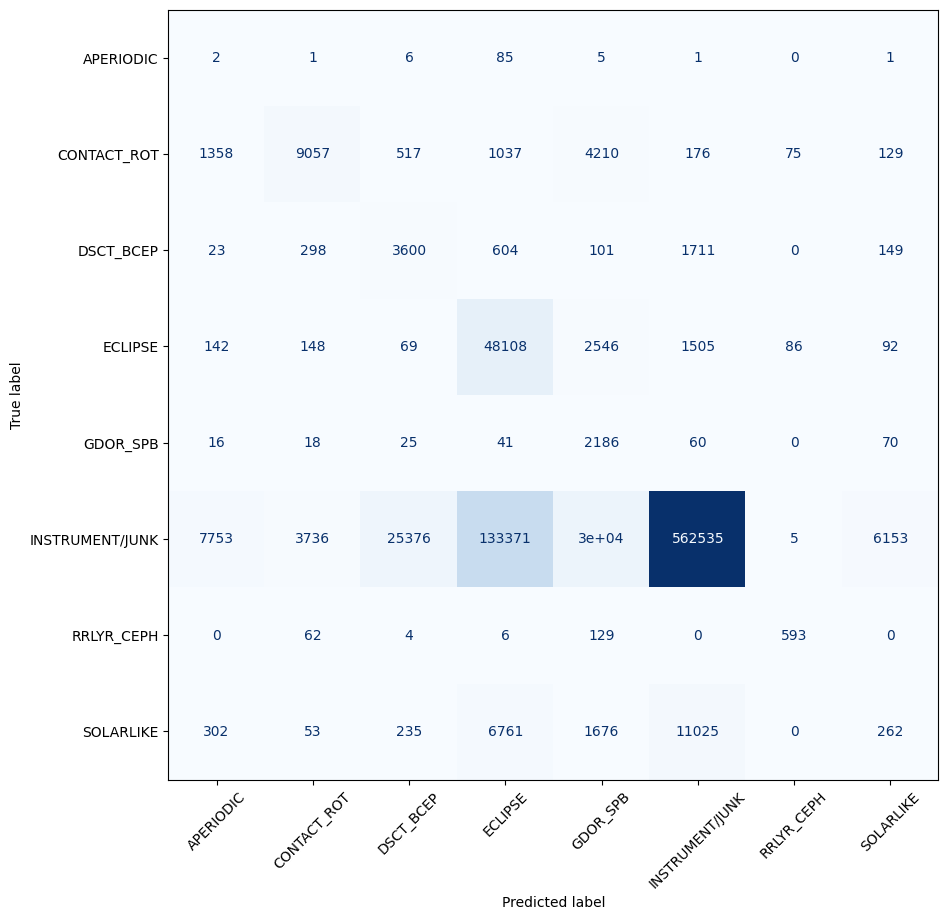

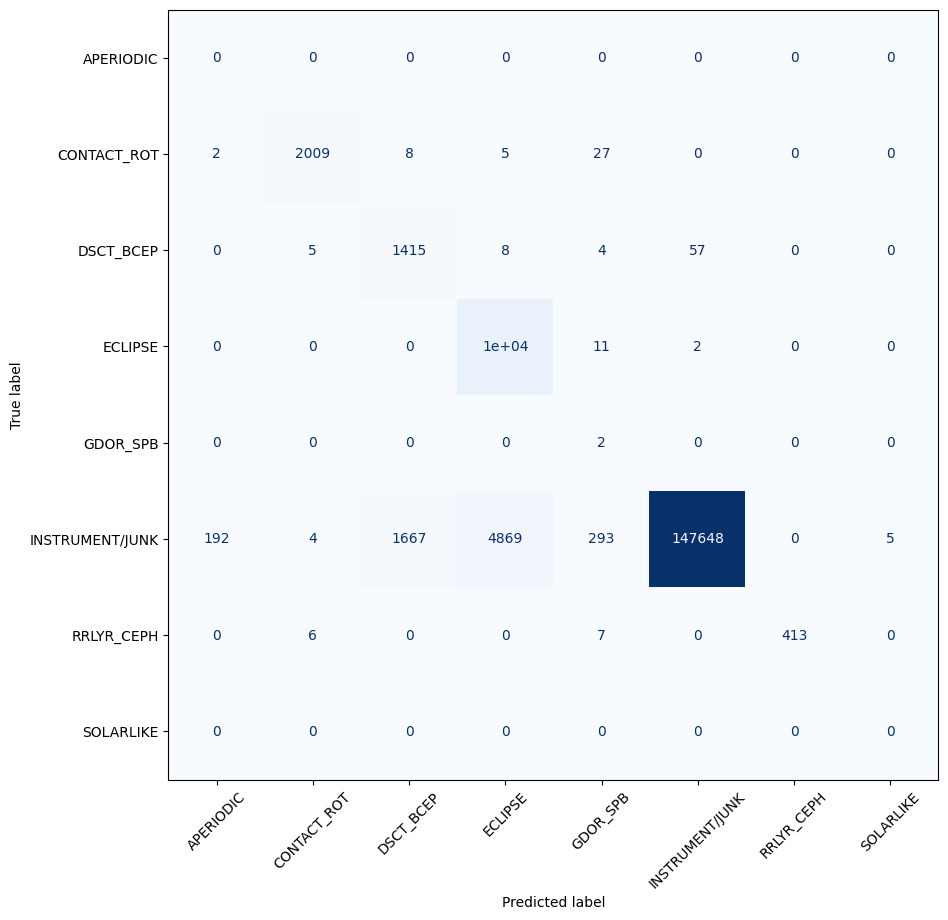

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay

only_high_conf = pl.col('best_nnet_proba').gt(0.75) & pl.col('best_rf_proba').gt(0.75)

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_true=df_join['best_rf_class'].to_numpy(), 
    y_pred=df_join['best_nnet_class'].to_numpy(), 
    ax=ax, cmap=plt.cm.Blues, xticks_rotation=45, colorbar=False
)

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_predictions(
    y_true=df_join.filter(only_high_conf)['best_rf_class'].to_numpy(), 
    y_pred=df_join.filter(only_high_conf)['best_nnet_class'].to_numpy(), 
    ax=ax, cmap=plt.cm.Blues, xticks_rotation=45, colorbar=False
)

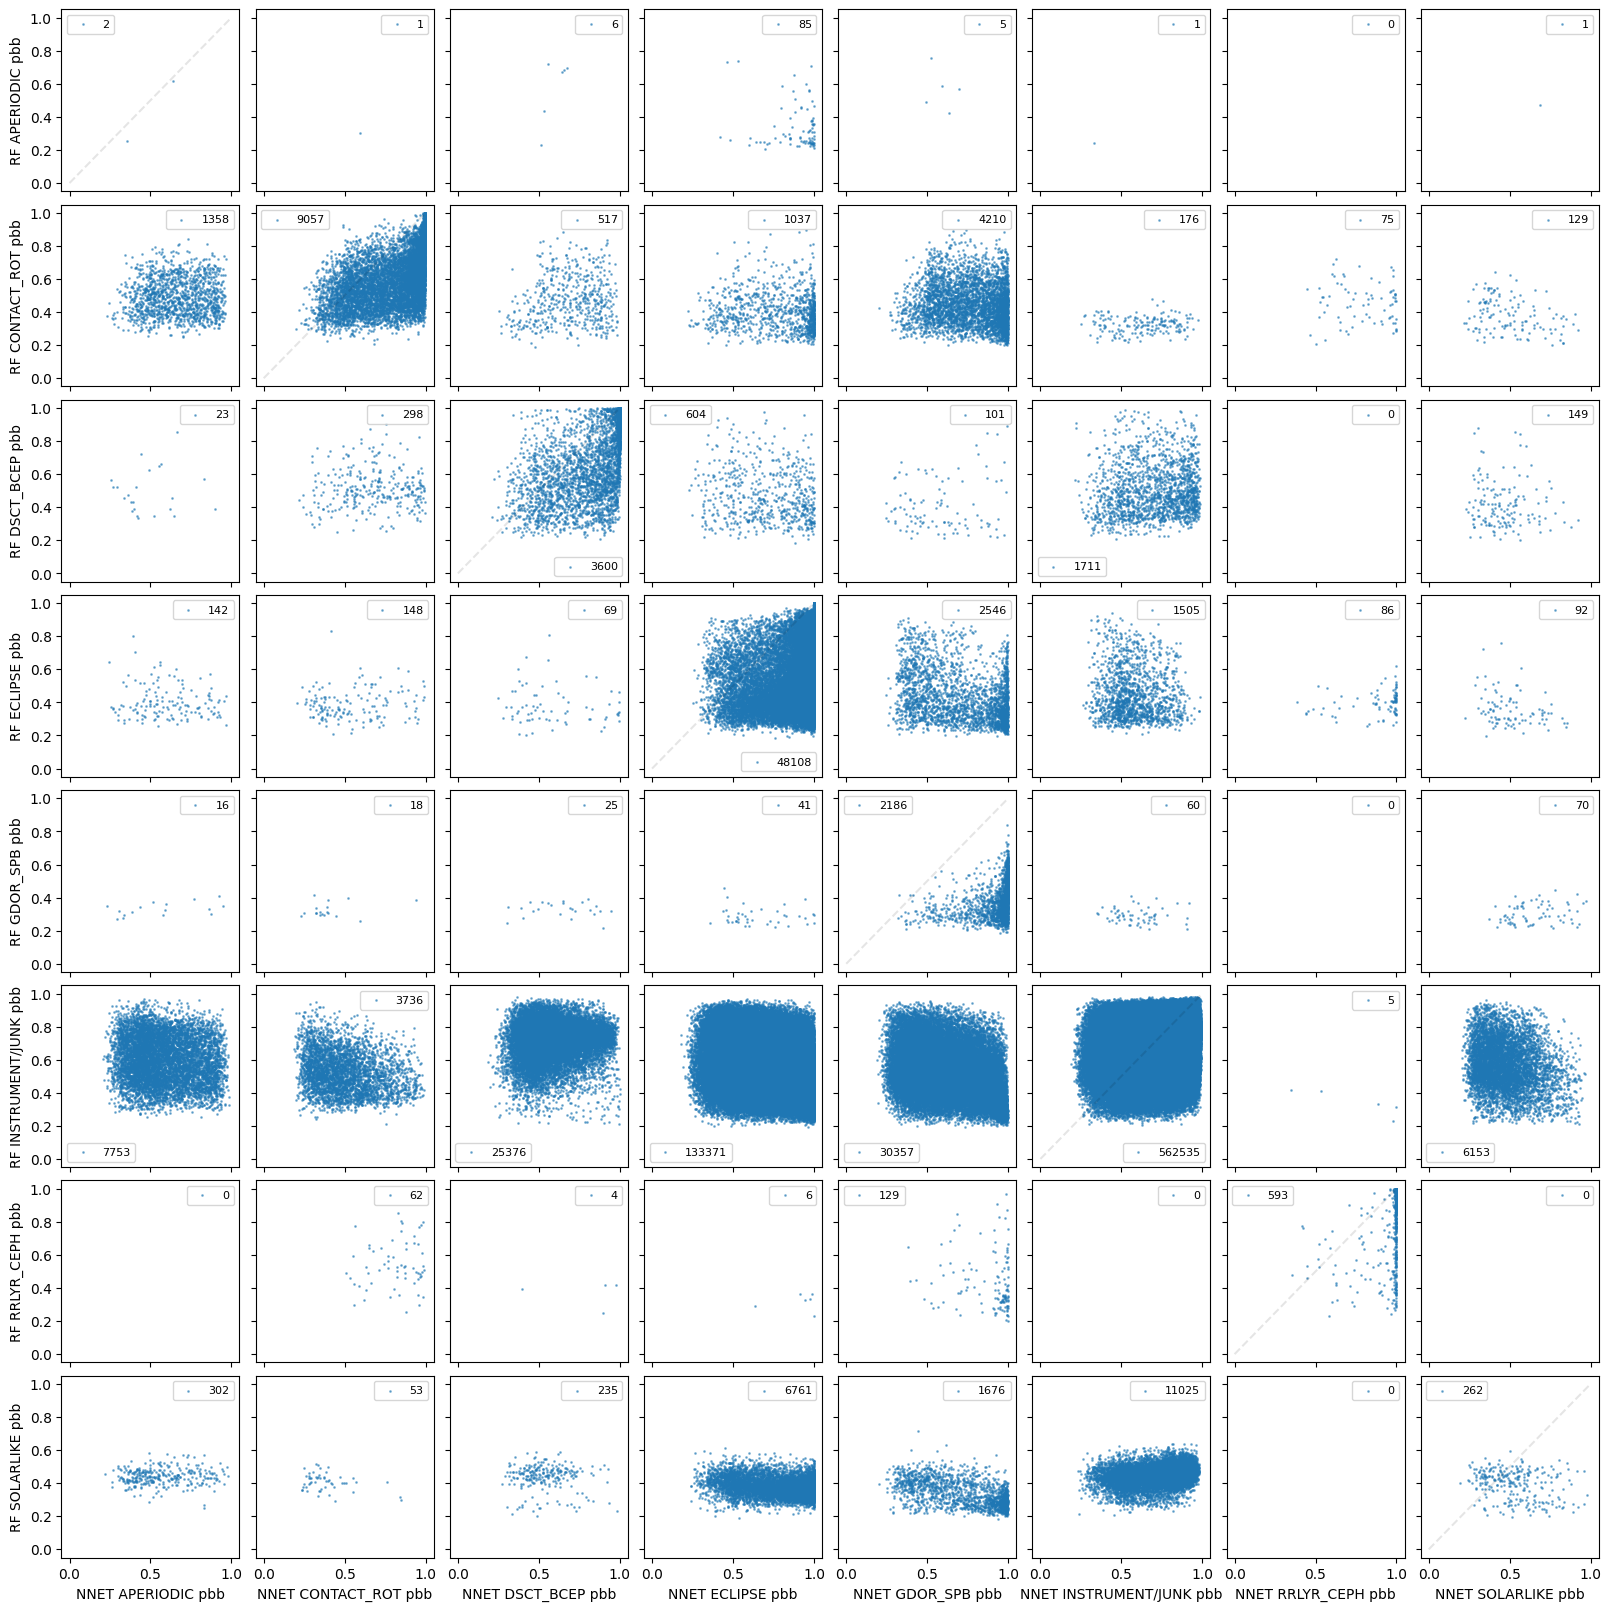

In [51]:
fig, axs = plt.subplots(len(clf.classes_), len(clf.classes_), figsize=(16, 16), constrained_layout=True, sharex=True, sharey=True)
for i, rf_class in enumerate(clf.classes_):
    for j, nnet_class in enumerate(clf.classes_):
        disagreements = df_join.filter(pl.col('best_rf_class').eq(rf_class) & pl.col('best_nnet_class').eq(nnet_class))
        axs[i, j].scatter(disagreements['best_nnet_proba'].to_numpy(), disagreements['best_rf_proba'].to_numpy(), alpha=0.5, s=1, label=len(disagreements))
        axs[i, j].legend(fontsize=8)
        if i == j:
            axs[i, i].plot([0, 1], [0, 1], ls='--', alpha=0.1, c='k')

for i, rf_class in enumerate(clf.classes_):
    axs[i, 0].set_ylabel(f'RF {rf_class} pbb')
for j, nnet_class in enumerate(clf.classes_):
    axs[-1, j].set_xlabel(f'NNET {nnet_class} pbb')

Text(0, 0.5, 'RF INSTRUMENT/JUNK probability')

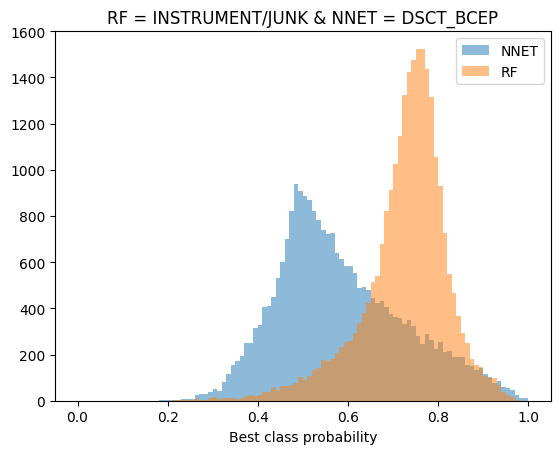

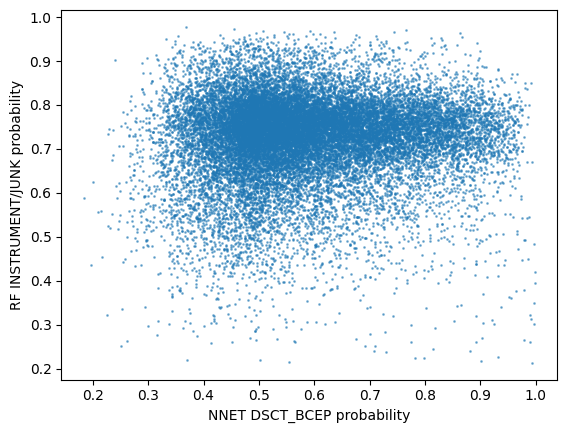

In [53]:
rf_class = 'INSTRUMENT/JUNK'
nnet_class = 'DSCT_BCEP'
disagreements = df_join.filter(
    pl.col('best_rf_class').eq(rf_class) & pl.col('best_nnet_class').eq(nnet_class)
#).filter(
#    pl.col('best_rf_proba').gt(0.75) & pl.col('best_nnet_proba').gt(0.9)
)
fig, ax = plt.subplots()
ax.hist(disagreements['best_nnet_proba'].to_numpy(), range=(0,1), bins=100, label='NNET', alpha=0.5)
ax.hist(disagreements['best_rf_proba'].to_numpy(), range=(0,1), bins=100, label='RF', alpha=0.5)
ax.set_xlabel('Best class probability')
ax.legend()
ax.set_title(f'RF = {rf_class} & NNET = {nnet_class}')

fig, ax = plt.subplots()
ax.scatter(disagreements['best_nnet_proba'].to_numpy(), disagreements['best_rf_proba'].to_numpy(), alpha=0.5, s=1)
ax.set_xlabel(f'NNET {nnet_class} probability')
ax.set_ylabel(f'RF {rf_class} probability')


In [57]:
disagreements.write_parquet('../results/INSTRUMENT_nnet_predicted_as_DSCT.parquet')

368


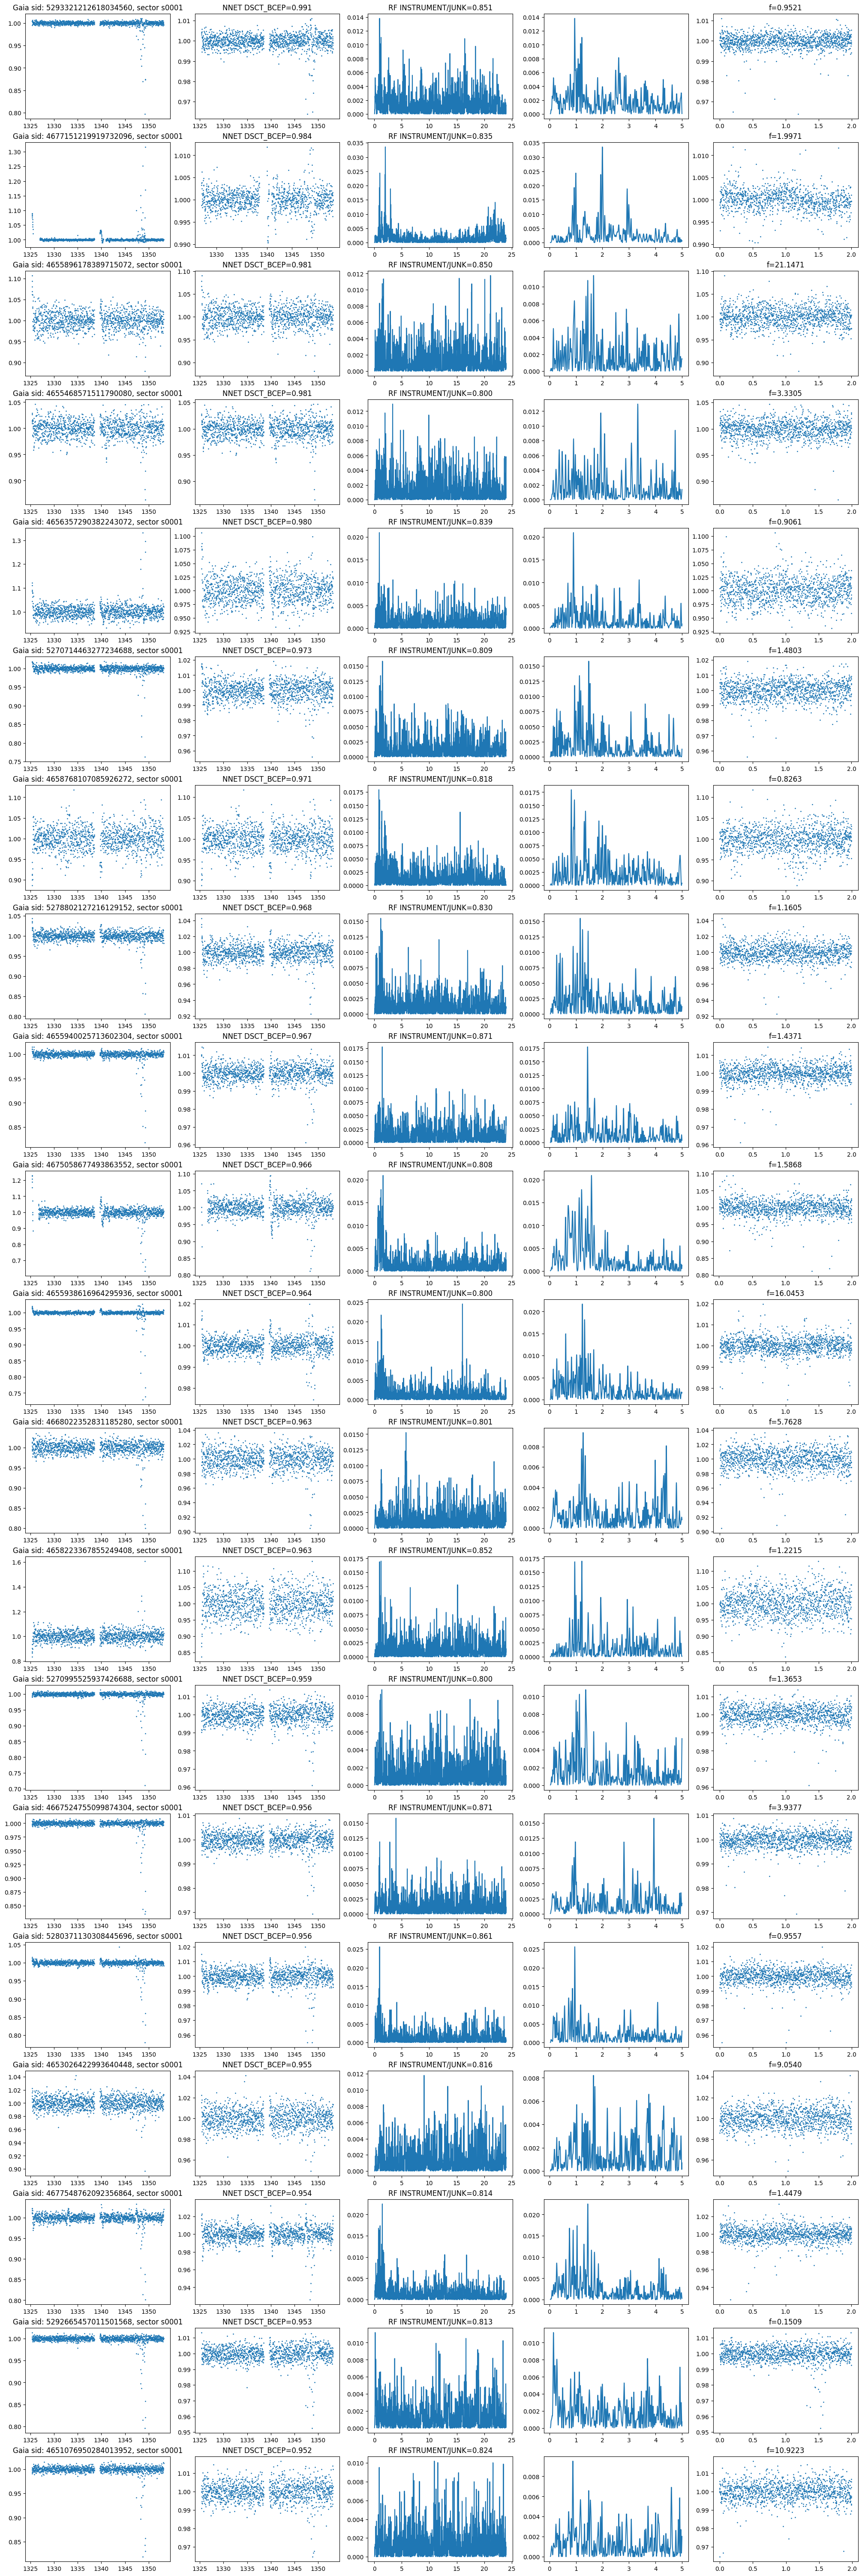

In [55]:
disagreements = df_join.filter(
    pl.col('best_rf_class').eq(rf_class) & pl.col('best_nnet_class').eq(nnet_class)
).filter(
    pl.col('best_rf_proba').gt(0.8) & pl.col('best_nnet_proba').gt(0.8)
).sort('best_nnet_proba', descending=True)
print(disagreements.height)
sub_df = disagreements.head(20)
n_plots = sub_df.height
fig, axs = plt.subplots(max(2, n_plots), 5, figsize=(20, 3*n_plots), constrained_layout=True, sharex=False)
for row, ax in zip(sub_df.iter_rows(named=True), axs):
    path_, rf_proba, nnet_proba = row['FilePath'], row['best_rf_proba'], row['best_nnet_proba']
    sid, sector = path_.split('-')[2:4]
    ax[0].set_title(f"Gaia sid: {sid}, sector {sector}")
    ax[1].set_title(f"NNET {nnet_class}={nnet_proba:0.3f}")
    ax[2].set_title(f"RF {rf_class}={rf_proba:0.3f}")
    time, flux, sector = read_fits_lc(path_)
    ax[0].scatter(time, flux, s=1)
    time_pre, flux_pre = preprocess_lc(time, flux, sector)
    ax[1].scatter(time_pre, flux_pre, s=1)
    freq, ampl, _ = compute_lombscargle_periodogram(time_pre, flux_pre)
    best_freq = freq[np.argmax(ampl)]
    ax[2].plot(freq, ampl)
    ax[3].plot(freq[freq<5], ampl[freq<5])
    ax[4].set_title(f"f={best_freq:0.4f}")
    ax[4].scatter(np.mod(time_pre, 2/best_freq)*best_freq, flux_pre, s=1)